# M14 · Les maths des ensembles — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m14_ensembles/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M14.1 à M14.5, M14.9 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M14.11 | La borne de Chernoff et la variance d'une moyenne pondérée · `chernoff_bound, variance_of_average` | 🔨 | ★ | 20 |
|  | M14.12 | Les poids de l'algorithme Hedge · `hedge_weights` | 🔨 | ★ | 15 |
| B | M14.13 | Simuler la moyenne de deux groupes de modèles corrélés, et retrouver aᵀΣa et son plancher | 🔬 | ★★ | 20 |
|  | M14.14 | Les poids exponentiels au fil des tours : quel expert domine, selon le learning rate | 🎨 | ★ | 15 |
| C | M14.15 | Chasse à l'erreur : P(X ≥ k) calculée comme P(X > k), des covariances oubliées, des poids non renormalisés | 🐛 | ★ | 15 |
|  | M14.16 | Un test qui vérifie que la borne de Chernoff majore la queue exacte de `scipy.stats`, sur une grille de n, p et a | 🛠️ | ★ | 15 |
|  | M14.17 | Défi : suivre le meilleur de dix experts avec Hedge sans connaître l'horizon, un regret sous la borne théorique sur 1 000 tours | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : la queue d'une loi binomiale et ses trois bornes, la variance d'une moyenne pondérée et les meilleurs poids, la limite $(1 + x/n)^n \to e^x$, les poids de Hedge et son regret, le gradient d'une loss par rapport aux prédictions, le plancher de variance de deux groupes de modèles.
- Écrire les trois fonctions de `mymath/ensembles.py` et les tester.
- Simuler un plancher de variance, tracer les poids de Hedge, chasser des erreurs, tester une borne, et relever un défi : Hedge sans connaître l'horizon.

**Rappel express.** $P(X \ge k) = \sum_{j \ge k}\binom{n}{j}p^j(1 - p)^{n-j}$ = `binom.sf(k - 1, n, p)` ; pour $a > p$, $P(X \ge na) \le e^{-n\,\mathrm{KL}(a \Vert p)}$ (Chernoff), avec $\mathrm{KL}(a \Vert p) = a\ln\frac{a}{p} + (1 - a)\ln\frac{1 - a}{1 - p} \ge 2(a - p)^2$ (Hoeffding : $e^{-2n(a - p)^2}$) ; $\mathbb{V}\big(\sum_i w_iX_i\big) = \mathbf{w}^\top\boldsymbol{\Sigma}\mathbf{w}$, meilleurs poids $\propto \boldsymbol{\Sigma}^{-1}\mathbf{1}$, variance minimale $\frac{1}{\mathbf{1}^\top\boldsymbol{\Sigma}^{-1}\mathbf{1}}$ ; une part commune laisse un plancher ; $(1 + x/n)^n \to e^x$, erreur relative $\approx -\frac{x^2}{2n}$ ; Hedge : $w_t[k] \propto e^{-\eta L_t[k]}$ (retrancher $\min_j L_t[j]$), $R_T \le \frac{\ln K}{\eta} + \frac{\eta T}{8}$, $\eta = \sqrt{8\ln K/T}$ donne $R_T \le \sqrt{\frac{T\ln K}{2}}$ ; sans $T$, $\eta_t = \sqrt{8\ln K/t}$ ; $\frac{\partial}{\partial F}e^{-yF} = -y\,e^{-yF}$, et pour Huber $-\operatorname{clip}(y - F, -\delta, \delta)$.

## Partie 0 · Vérifier tes exercices papier (✏️ M14.1 à M14.5, 🔗 M14.9)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une liste `[0.15, -2]` ; dans une liste, une fraction s'écrit entre guillemets, `["1/4", "3/4"]`, ou comme un calcul, sans guillemets : `[1/4, 3/4]`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import math

import sympy

R = sympy.Rational


def floats(values):
    """SymPy numbers as a list of Python floats."""
    return [float(v) for v in values]


def tail(n, p, k):
    """P(X ≥ k) for X of law B(n, p), as an exact sum."""
    return sum(sympy.binomial(n, j) * p ** j * (1 - p) ** (n - j) for j in range(k, n + 1))


def kl(a, p):
    """KL(a ‖ p) between the Bernoulli laws of parameters a and p, in nats (0 < a, p < 1)."""
    return a * sympy.log(a / p) + (1 - a) * sympy.log((1 - a) / (1 - p))


P_1 = R(9, 10)                                                                               # M14.1
S_2, ONE_2 = sympy.Matrix([[3, 1, -1], [1, 5, -1], [-1, -1, 2]]), sympy.ones(3, 1)          # M14.2


def quad_2(w, diagonal=False):
    """wᵀ S_2 w (with the variances only when diagonal)."""
    S = sympy.diag(*S_2.diagonal()) if diagonal else S_2
    return (w.T * S * w)[0]


W_2 = sympy.Matrix([R(1, 4), R(1, 4), R(1, 2)])
INV_2 = S_2.inv() * ONE_2                                  # Σ⁻¹1
WSTAR_2 = INV_2 / sum(INV_2)
X_3 = R(39, 100)                                           # M14.3: x = 6 × 0.065 over the 6 years


def factor_3(N, x=X_3):
    """(1 + x/N)^N."""
    return (1 + x / N) ** N


L_4 = [[0, 1, 1, 0, 1], [1, 0, 1, 0, 0], [0, 1, 0, 1, 0]]                                  # M14.4: eta = ln 3
CUM_4 = [[sum(row[k] for row in L_4[:t]) for k in range(5)] for t in range(4)]   # before each round, then after the last


def law_4(values, sign=-1):
    """The weights 3^(sign · value), normalized."""
    raw = [R(3) ** (sign * v) for v in values]
    return [r / sum(raw) for r in raw]


W_4 = [law_4(c) for c in CUM_4]
ALG_4 = sum(sum(w * l for w, l in zip(W_4[t], L_4[t])) for t in range(3))
AFTER_4 = sum(sum(w * l for w, l in zip(W_4[t + 1], L_4[t])) for t in range(3))   # with the weights after each round
BEST_4, WORST_4 = min(CUM_4[-1]), max(CUM_4[-1])
Y_5, F_5 = [1, 1, -1, -1, 1], [2, R(-1, 2), R(-3, 2), R(3, 10), 0]                         # M14.5
M_5 = [y * f for y, f in zip(Y_5, F_5)]
E_5 = [sympy.exp(-m) for m in M_5]
T_5, P_5 = [R(24, 10), R(-1, 2), 1, R(58, 10)], [R(19, 10), R(6, 10), R(13, 10), R(31, 10)]
RES_5, DELTA_5 = [t - p for t, p in zip(T_5, P_5)], R(4, 5)
CLIP_5 = [max(-DELTA_5, min(DELTA_5, r)) for r in RES_5]
HUBER_5 = sum(r ** 2 / 2 if abs(r) <= DELTA_5 else DELTA_5 * (abs(r) - DELTA_5 / 2) for r in RES_5)
VA_9, VB_9, CAB_9, S_9 = R(7, 10), R(9, 10), R(3, 10), R(5, 2)                            # M14.9


def var_9(ma, mb, cov=CAB_9):
    """The variance of the mean of ma models of group A and mb models of group B."""
    m = ma + mb
    return (ma ** 2 * VA_9 + mb ** 2 * VB_9 + 2 * ma * mb * cov) / m ** 2 + S_9 / m


FLOOR_9 = (VA_9 + VB_9 + 2 * CAB_9) / 4                    # the variance of (Z_A + Z_B)/2
al = sympy.symbols("alpha")
MIX_9 = al ** 2 * VA_9 + (1 - al) ** 2 * VB_9 + 2 * al * (1 - al) * CAB_9
ALPHA_9 = sympy.solve(sympy.diff(MIX_9, al), al)[0]

**Ex M14.1 — La fiabilité d'un système « k parmi n » : au moins k composants qui marchent**

In [3]:
wbm.record("M14.1a", float(tail(9, P_1, 7)), decimals=4, mistakes={"« au moins 7 » compte aussi X = 7 : P(X ≥ 7), pas P(X > 7)": float(tail(9, P_1, 8))})
wbm.record("M14.1b", float(sympy.binomial(9, 7) * P_1 ** 7 * (1 - P_1) ** 2), decimals=4, mistakes={"il y a C(9, 7) façons de choisir les 7 machines qui marchent": float(P_1 ** 7 * (1 - P_1) ** 2)})
wbm.record("M14.1c", float(9 * (1 - P_1)), decimals=6, mistakes={"F compte les PANNES : une machine tombe en panne avec la probabilité 1 − 0,9": float(9 * P_1)})
wbm.record("M14.1d", float(1 - tail(9, P_1, 7)), decimals=4, mistakes={"« au moins 3 pannes » compte aussi F = 3 : P(F ≥ 3), pas P(F > 3)": float(1 - tail(9, P_1, 6))})
wbm.record("M14.1e", float(9 * kl(R(1, 3), R(1, 10))), decimals=4, mistakes={"KL(a ‖ p) : d'abord la proportion a = 1/3 de l'événement, puis le paramètre 0,1 de la loi": float(9 * kl(R(1, 10), R(1, 3))), "l'exposant est n KL(a ‖ p), avec n = 9": float(kl(R(1, 3), R(1, 10)))})
wbm.record("M14.1f", float(sympy.exp(-18 * (R(1, 3) - R(1, 10)) ** 2)), decimals=4, mistakes={"Hoeffding : e^(−2n(a − p)²), avec le 2": float(sympy.exp(-9 * (R(1, 3) - R(1, 10)) ** 2))})
wbm.record("M14.1g", float(9 * (1 - P_1) / 3), decimals=4, mistakes={"la borne de Markov de P(F ≥ 3) utilise 𝔼[F], l'espérance du nombre de PANNES": float(9 * P_1 / 3)})
wbm.record("M14.1h", float(tail(12, P_1, 10)), decimals=4, mistakes={"« au moins 10 » compte aussi X = 10 : P(X ≥ 10), pas P(X > 10)": float(tail(12, P_1, 11))})

WBM_ANSWER {"coarse_any": {"0": ["352a4eb8ba4d351ae6d470a026d68ba3105cac6b56339af6a87bd7e1a3b9b9ce"], "1": ["ceef623523d6ecf055f4c16d5b3880d18fcf1505bdd94121d1b09e58bd205465"]}, "coarser": {"2": ["4ffa0b6a82e758be679a688f2068354bb67a792ecf97eb8d0fd27e48b05da0c7"]}, "decimals": 4, "hash": "e20c2034e29d50046a28533ce8a54d47943da35bc87ed5259f8ff21d2621fb11", "hash_coarse": "ef36d314adadbc5763e2534d9b1bde3d21931dde3367ac9ee3ef8d51019901ba", "id": "M14.1a", "kind": "float", "magnitude": -1, "mistakes": {"44c8d10d8e7fe944410840d7e7519bbcda617f4051a36406736f6b2057a30dca": "« au moins 7 » compte aussi X = 7 : P(X ≥ 7), pas P(X > 7)"}, "sign": 1}
📝 Ex M14.1a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["ba22bda54ac151b63faafa2a77d98d15329ed1286c2463371c602480d29669dc"]}, "coarser": {"2": ["06eafdaf4e93cd5e7276fb93075b1b186be924a7d6aa02a00fa30f1842d39039"]}, "decimals": 4, "hash": "4a4670f4ffdb26bf3489464cd8fbe9269d1fc4f2ee17dacf3ed1dc701713af06", "hash_coarse": "9

**Ex M14.2 — La variance de la moyenne de trois mesures corrélées, par la matrice de covariance**

In [4]:
wbm.record("M14.2a", quad_2(ONE_2 / 3), kind="fraction", simplified=True, mistakes={"les covariances comptent : wᵀΣw fait la somme des 9 termes wᵢwⱼΣᵢⱼ, pas seulement des variances": quad_2(ONE_2 / 3, diagonal=True), "la moyenne a les poids 1/3 : chaque terme Σᵢⱼ est multiplié par 1/9": sum(S_2)})
wbm.record("M14.2b", quad_2(ONE_2 / 3, diagonal=True), kind="fraction", simplified=True, mistakes={"chaque variance est pondérée par wᵢ², le carré du poids 1/3": S_2.trace() / 3})
wbm.record("M14.2c", quad_2(W_2), kind="fraction", simplified=True, mistakes={"les covariances comptent : wᵀΣw fait la somme des 9 termes wᵢwⱼΣᵢⱼ": quad_2(W_2, diagonal=True)})
wbm.record("M14.2d", floats(WSTAR_2), decimals=6, mistakes={"des poids de somme 1 : divise Σ⁻¹1 par la somme de ses coordonnées": floats(INV_2)})
wbm.record("M14.2e", quad_2(WSTAR_2), kind="fraction", simplified=True, mistakes={"la variance minimale est 1/(1ᵀΣ⁻¹1), l'INVERSE de la somme des coordonnées de Σ⁻¹1": sum(INV_2)})
wbm.record("M14.2f", float(S_2[0, 1] / sympy.sqrt(S_2[0, 0] * S_2[1, 1])), decimals=4, mistakes={"la corrélation divise la covariance par le produit des ÉCARTS-TYPES, les racines des variances": float(S_2[0, 1] / (S_2[0, 0] * S_2[1, 1]))})

WBM_ANSWER {"hash": "11cbb4b8d6a25d1949549b39b3e62c9884c15ddc8bcda8fe24eab543ea91c531", "id": "M14.2a", "kind": "fraction", "mistakes": {"3ec2c5a2d05d99dbf14b57298e89578a72d4e4d9b07100c8ac85b828c31fc72a": "la moyenne a les poids 1/3 : chaque terme Σᵢⱼ est multiplié par 1/9", "e9eeedb769715d38a7430781a76ec945d93a93539be942370fe1a33ee6132202": "les covariances comptent : wᵀΣw fait la somme des 9 termes wᵢwⱼΣᵢⱼ, pas seulement des variances"}, "sign": 1, "simplified": true}
📝 Ex M14.2a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "d6c79c1f1731a836cfded1bae2e4d55bf40e6346f672bec73b458b91934bef43", "id": "M14.2b", "kind": "fraction", "mistakes": {"ab624ca5dde09ad5a6e36f0ed3cb64863a061799e6d48c7988d961fcb7028695": "chaque variance est pondérée par wᵢ², le carré du poids 1/3"}, "sign": 1, "simplified": true}
📝 Ex M14.2b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "9e828cab8f69cd832d12dba4aa4cb36d544f190e646108f4c02d9e623d8ec807", "id": "M14.2c", "kind": "fraction", "mistakes

**Ex M14.3 — (1 + x/n)ⁿ pour quelques n, et des intérêts composés en continu**

In [5]:
wbm.record("M14.3a", float(factor_3(6)), decimals=6, mistakes={"sur 6 ans, le facteur d'une année s'applique 6 fois": 1.065})
wbm.record("M14.3b", float(factor_3(24)), decimals=6, mistakes={"sur 6 ans, 4 versements par an font 24 versements en tout": float(factor_3(4, R(65, 1000)))})
wbm.record("M14.3c", float(factor_3(312)), decimals=6, mistakes={"sur 6 ans, 52 versements par an font 312 versements en tout": float(factor_3(52, R(65, 1000)))})
wbm.record("M14.3d", float(sympy.exp(X_3)), decimals=6, mistakes={"la limite porte sur les 6 ans, pas sur une seule année": float(sympy.exp(R(65, 1000)))})
wbm.record("M14.3e", float(factor_3(24) / sympy.exp(X_3) - 1), decimals=6, mistakes={"l'erreur relative est (valeur − limite)/limite : attention au signe": float(1 - factor_3(24) / sympy.exp(X_3))})
wbm.record("M14.3f", float(-X_3 ** 2 / 48), decimals=6, mistakes={"N compte TOUS les versements des 6 ans": float(-X_3 ** 2 / 8), "x et N portent tous deux sur les 6 ans": float(-R(65, 1000) ** 2 / 8), "x porte sur les 6 ans, comme N": float(-R(65, 1000) ** 2 / 48)})
wbm.record("M14.3g", float(R(11, 10) ** 30 / sympy.exp(3) - 1), decimals=3, mistakes={"l'erreur relative est (valeur − limite)/limite : attention au signe": float(1 - R(11, 10) ** 30 / sympy.exp(3)), "g) demande l'erreur relative vraie, pas son approximation −x²/(2n)": -0.15})
wbm.record("M14.3h", next(n for n in range(1, 10 ** 4) if R(9, 2 * n) < R(8, 1000)), mistakes={"n est entier, et doit vérifier l'inégalité : vérifie-la pour ta valeur": 562})

WBM_ANSWER {"coarse_any": {"0": ["e61c9ac2a23c63e98f1b4050f45d2513f3f921de828bc4fa6b78593d3fffa9de"]}, "coarser": {"1": ["1ec7a15af15ad5a549390f45b581010c08ed2d29295a815f38e7eedf05dcffce"], "2": ["11095023cf3a9ba951963a26383179c09ae0bcd378ef05ba3c6ff3079f9fb9ef"], "3": ["b6dc7374716d8a93f5fa2fd946cda822d88b38d631d4445478d1c44222e7cd3a"], "4": ["8913d245b9a88a8790629b46f546cc5f26ef57f0f55c65b516d2312465c44ab2"]}, "decimals": 6, "hash": "6ffb998f6a2d8838e67deb23c8ad93c318de37a2e44ac0f14cf88752b0c04cb0", "hash_coarse": "6d64b2205e7c847f8f4c095c9f5b23dbb37d7e499e6fb56ec35124a6ccb4f30b", "id": "M14.3a", "kind": "float", "magnitude": 0, "mistakes": {"fb97caaedcf39f299e48a6d206fc1f98acb622f5b378506e37524591a7425016": "sur 6 ans, le facteur d'une année s'applique 6 fois"}, "sign": 1}
📝 Ex M14.3a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["44c2e44dd288580dca99ca8db36c1a97336870dacfba764673ea6be74bf064e6"]}, "coarser": {"1": ["62561c2d149c5bad294a668b543a71a1de3

**Ex M14.4 — Les poids exponentiels de cinq experts après trois tours**

In [6]:
wbm.record("M14.4a", floats(W_4[1]), decimals=6, mistakes={"des poids : divise par leur somme": floats(R(3) ** -v for v in CUM_4[1]), "le poids est proportionnel à 3^(−L) : une grande loss, un PETIT poids": floats(law_4(CUM_4[1], sign=1))})
wbm.record("M14.4b", floats(W_4[2]), decimals=6, mistakes={"le poids utilise la loss CUMULÉE sur tous les tours précédents, pas celle du dernier tour": floats(law_4(L_4[1]))})
wbm.record("M14.4c", floats(W_4[3]), decimals=6, mistakes={"le poids utilise la loss CUMULÉE sur tous les tours précédents, pas celle du dernier tour": floats(law_4(L_4[2]))})
wbm.record("M14.4d", ALG_4, kind="fraction", simplified=True, mistakes={"chaque tour se joue avec les poids d'AVANT le tour : Σ_t w_t · ℓ_t": AFTER_4})
wbm.record("M14.4e", int(BEST_4), mistakes={"le meilleur expert a la PLUS PETITE loss totale": int(WORST_4)})
wbm.record("M14.4f", float(ALG_4 - BEST_4), decimals=4, mistakes={"le regret compare ta loss à celle du MEILLEUR expert": float(ALG_4 - WORST_4)})
wbm.record("M14.4g", float(sympy.log(5) / sympy.log(3) + 3 * sympy.log(3) / 8), decimals=3, mistakes={"K = 5 experts : le premier terme est ln 5 / η": float(1 + 3 * sympy.log(3) / 8)})
wbm.record("M14.4h", float(sympy.sqrt(8 * sympy.log(5) / 3)), decimals=4, mistakes={"K = 5 experts et T = 3 tours : ne les échange pas": float(sympy.sqrt(8 * sympy.log(3) / 5))})

WBM_ANSWER {"array_rounded": {"1": "43cddcf2b8819c9f11b635976ed342161537fc1b5122773ba9c07c581c80f079", "2": "683a6ef688184a15f8fb0412c019bd264643e01431d5284f9c21513ee3e3fbff", "3": "40315db1f5abdf6af53c85a702b673c82d55521eedd0edfa4a0c3507d26e9ad4", "4": "270eb32757009fc874eb9d2baf4e5d742f4730e592330ff6850c69b69bc93671", "5": "34ae5fa1ba58159a2700fe6aed6e3093acc9947bd3de2f1246bfe02496da64b5"}, "decimals": 6, "element_coarse": [["c24abe58d599b8a287c6b51538ce57816103ba4702c898e9aaaa3383fae9fe49"], ["7a077eb12e58e0cbe57ad9f2ae8d702cae0e48932421214d9f5464f88157dc90"], ["13b29b3cc927189bab0e57b36983e60960d74d1f3ece3467d8a7604465e7bc57"], ["677a18944f1c41eace3be24faab120700f416082c305e553cc2bb78ef33ecccd"], ["30ed03be3c37fc2634cccffa3f7ec97d3996e0796323602c6d737af34a552fc8"]], "element_coarse_any": [["ca78d14994f24125cf7e09de82bb6e72820b5fe13e6b03a4bb5c10190fc711e5", "04ad7d83de2764678701c7f9ffa80309d04c0614c45f07b832b7ee4f3794a117", "67bc9cc74de38c59231116187d8963943736dfc5784a20f28147f1cbeb

**Ex M14.5 — Le gradient de la loss exponentielle e^(−yF) et de la loss de Huber par rapport aux prédictions, et les poids exponentiels qu'il fait apparaître**

In [7]:
wbm.record("M14.5a", floats(M_5), decimals=6, mistakes={"la marge multiplie le score par le label : y_i F_i": floats(F_5)})
wbm.record("M14.5b", float(sum(E_5)), decimals=3, mistakes={"la loss exponentielle est e^(−yF), avec le signe moins": float(sum(sympy.exp(m) for m in M_5))})
wbm.record("M14.5c", floats(-y * e for y, e in zip(Y_5, E_5)), decimals=3, mistakes={"la dérivée de e^(−yF) en F fait sortir −y : le label compte": floats(-e for e in E_5), "la dérivée de e^(−yF) en F fait sortir −y : attention au signe": floats(y * e for y, e in zip(Y_5, E_5)), "c) demande la DÉRIVÉE de chaque terme en F_i, pas sa valeur": floats(E_5)})
wbm.record("M14.5d", floats(e / sum(E_5) for e in E_5), decimals=4, mistakes={"un exemple mal classé (marge négative) a une GRANDE loss e^(−yF)": floats(sympy.exp(m) / sum(sympy.exp(v) for v in M_5) for m in M_5)})
wbm.record("M14.5e", 1 + max(range(5), key=lambda i: float(E_5[i])), mistakes={"numérote les exemples à partir de 1, comme l'énoncé": max(range(5), key=lambda i: float(E_5[i]))})
wbm.record("M14.5f", floats(-c for c in CLIP_5), decimals=6, mistakes={"au-delà de δ, la loss de Huber est linéaire : son gradient est coupé à ±δ": floats(-r for r in RES_5), "la dérivée en F de ℓ(y − F) fait sortir un signe moins": floats(CLIP_5)})
wbm.record("M14.5g", float(HUBER_5), decimals=4, mistakes={"au-delà de δ, la loss de Huber est δ(|r| − δ/2), pas r²/2": float(sum(r ** 2 / 2 for r in RES_5))})

WBM_ANSWER {"decimals": 6, "element_coarse": [["0af197ed3acb508f97904f471179b6b458fb4f25c3d501531b1dac24c2ff28fa"], ["f0acf1fd269fc2b46ec4f0285c50b5f38413e8d40d65029bff73c5dd76712534"], ["1486dbfbdb8d950560462fa4e2f4239ad9aa18aa3f3339845fba5ea56469eadc"], ["10af90325e64354c2b4e1c407901660341b5b0ea755fd9d0cb87c8cd9b2de686"], ["5ed1ed4b5c214f0ef636e19f067cc65cdff350fb5e94ada2acf6c114a1afde5f"]], "element_coarse_any": [["d99277f84049871efea778bb25b09eaebe903a383ee354590645d2782365c125", "c8059b7e1c50b8bfbc338d9f75a016b447a80666e63b9ddc6b483c9e8c671db4", "8ff1c4a9fddc3fac2e291928cdb221127eee0d56d35eee419edf06877ef3034a", "71f9a27a916b2190e17ef85bac15254f885eb95f18299d9a7005f7c0dd245fe8", "4e1f42503a2bc6c2103c6747e20794b1ed68a1912ebc0de59ca4dc3330d7a2db"], ["a71025d6a1d58c6d89659f398b7f95f7552650bddc2e899ca59955b5a60cb460", "5c7a9439196af6f7893aee2a8e4b4f499310456a6c28c24e3972f17bc95e1b44", "4bba04b544e7b1ef306cb42a8c96ea590fc1ff598ea6a18493bf36f0f9f59b61", "da22bb8d9088b8c1cc60b244c7698948

**Ex M14.9 — Pont : ajouter des modèles très corrélés ne sert presque à rien, un plancher de variance sur deux groupes de modèles**

In [8]:
wbm.record("M14.9a", var_9(5, 5), kind="fraction", simplified=True, mistakes={"Z_A et Z_B sont corrélées : n'oublie pas leur covariance": var_9(5, 5, cov=0), "la moyenne porte sur les 2m = 10 modèles, pas sur m": FLOOR_9 + R(5, 10)})
wbm.record("M14.9b", FLOOR_9, kind="fraction", simplified=True, mistakes={"Z_A et Z_B sont corrélées : n'oublie pas leur covariance": (VA_9 + VB_9) / 4})
wbm.record("M14.9c", FLOOR_9 / var_9(5, 5), kind="fraction", simplified=True, mistakes={"c) demande la part du plancher DANS la variance de a), un nombre entre 0 et 1": var_9(5, 5) / FLOOR_9, "Z_A et Z_B sont corrélées : n'oublie pas leur covariance": (VA_9 + VB_9) / 4 / var_9(5, 5, cov=0)})
wbm.record("M14.9d", VA_9, kind="fraction", simplified=True, mistakes={"quand m → ∞, les parts propres se moyennent et disparaissent": VA_9 + S_9})
wbm.record("M14.9e", ALPHA_9, kind="fraction", simplified=True, mistakes={"α est la proportion de modèles du groupe A": 1 - ALPHA_9})
wbm.record("M14.9f", MIX_9.subs(al, ALPHA_9), kind="fraction", simplified=True, mistakes={"Z_A et Z_B sont corrélées : n'oublie pas leur covariance": VA_9 * VB_9 / (VA_9 + VB_9)})
wbm.record("M14.9g", var_9(10, 0), kind="fraction", simplified=True, mistakes={"les 10 modèles du groupe A partagent Z_A : sa variance ne se divise pas par 10": (VA_9 + S_9) / 10})
wbm.record("M14.9h", var_9(100, 10), kind="fraction", simplified=True, mistakes={"Z_A et Z_B sont corrélées : n'oublie pas leur covariance": var_9(100, 10, cov=0)})

WBM_ANSWER {"hash": "1254bc3d58077e9de5f7809510cb5a4965eb91d6e6e405a1939cd437b0f8e916", "id": "M14.9a", "kind": "fraction", "mistakes": {"7fcaa7a061f7f0362adde1851e4eac4db87fe4e03e50b6f8542afe90128b7bf4": "la moyenne porte sur les 2m = 10 modèles, pas sur m", "e5b8f74331318a0c8f2154413abdcdfa023376e0256e710b8b821d20183f8490": "Z_A et Z_B sont corrélées : n'oublie pas leur covariance"}, "sign": 1, "simplified": true}
📝 Ex M14.9a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "415f8511e73f7a33b70b29daa49fd1e89e079d42f8f9268a1bc2e5272009461c", "id": "M14.9b", "kind": "fraction", "mistakes": {"ca02ce02905457325091bb04776933ede3e36799a4134f17a0f0a1173bd40d7e": "Z_A et Z_B sont corrélées : n'oublie pas leur covariance"}, "sign": 1, "simplified": true}
📝 Ex M14.9b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "c3da0a5fcb718eea6f6745b763cb1a67e90b8ac17e9f84a98de2f6822b48d2b4", "id": "M14.9c", "kind": "fraction", "mistakes": {"cc26d3dc12e0c31d9cd6b912a8a474a2fb9b3240ba658c5948587

## Partie A · Ta librairie : la borne de Chernoff, la variance d'une moyenne et les poids de Hedge

Fiche §1, §2 et §4. Les trois fonctions de `mymath/ensembles.py`, et leurs tests.

In [9]:
# Tools of the notebook (parts A to C)
import ast
import inspect
import io
import linecache
import math
import re
import textwrap
import time
import tokenize
import warnings
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom

from wbm.nbtools import StopCheck, checked, drawn, filled, fr, own_code, run_pytest_group, verdict


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M14.11 — La borne de Chernoff et la variance d'une moyenne pondérée · `chernoff_bound, variance_of_average` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la borne de Chernoff d'une queue binomiale et la variance d'une moyenne pondérée de variables corrélées, et vérifier que la borne majore la queue exacte.  
**Prérequis :** fiche §1 et §2 · **mymath :** `ensembles.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/ensembles.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy et le module `math` sont permis ; SciPy et scikit-learn sont interdits (les tests comparent tes résultats à ceux de `scipy.stats` et `scipy.special`, et un test vérifie que tu ne t'en sers pas). Ne modifie jamais les tableaux reçus : travaille sur une copie, `np.array(x, dtype=float)`. Les nombres se rendent en `float` de Python, les vecteurs et les matrices en tableaux NumPy de flottants.

Écris, en suivant les docstrings (fiche §1 et §2) :
- `chernoff_bound(n, p, a)` : `ValueError` si $n$ n'est pas un entier $\ge 0$, ou si $p$ ou $a$ sort de $[0, 1]$ ; `1.0` si $a \le p$ (la borne ne dit rien) ; `0.0` si $p = 0 < a$ (l'événement est impossible) ; sinon $e^{-n\,\mathrm{KL}(a \Vert p)}$, avec $\mathrm{KL}(a \Vert p) = a\ln\frac{a}{p} + (1 - a)\ln\frac{1 - a}{1 - p}$ en nats, où $0\ln 0$ compte pour 0 (le cas $a = 1$) ;
- `variance_of_average(cov, weights=None)` : `ValueError` si `cov` n'est pas une matrice carrée symétrique, si les poids n'ont pas la bonne longueur, ont une valeur négative ou une somme différente de 1, ou si le résultat est négatif au-delà de l'arrondi ; sinon $\mathbf{w}^\top\boldsymbol{\Sigma}\mathbf{w}$, avec les poids $\frac{1}{M}$ quand `weights` est omis.

La vérification calcule, avec les données de la cellule fournie :
- a) `chernoff_bound(32, 0.24, 0.45)`, la borne de $P(X \ge 14{,}4)$ pour $X$ de loi $\mathcal{B}(32 ;\ 0{,}24)$ (6 décimales) ;
- b) `chernoff_bound(32, 0.24, 0.15)`, un cas où $a \le p$ ;
- c) `variance_of_average(COV_11)`, la variance de la moyenne simple de quatre variables de matrice de covariance `COV_11` (6 décimales) ;
- d) `variance_of_average(COV_11, weights=W_11)` (6 décimales) ;
- e) vrai ou faux : sur la grille de la cellule fournie (4 valeurs de $n$, 4 de $p$, 21 de $a$), ta borne est toujours au-dessus de la queue exacte $P(X \ge na)$, calculée par `binom.sf(math.ceil(n * a - 1e-9) - 1, n, p)` de `scipy.stats` ;
- f) le nom de l'erreur levée par `variance_of_average(COV_11, weights=[0.2, 0.3, 0.3, 0.3])`.

Dans ta copie : calcule $\mathrm{KL}(0{,}45 \Vert 0{,}24)$ à la main, puis a), et compare-la à la borne de Hoeffding $e^{-2n(a - p)^2}$ et à la queue exacte $P(X \ge 15)$. Que donnerait c) sans les covariances, et pourquoi c) est-il plus grand ? La grille de e) contient `a = np.linspace(0, 1, 21)[12]`, qui vaut `0.6000000000000001` : que vaut `25 * a`, et quelle queue calculerait `math.ceil(n * a) - 1` sans le `- 1e-9` ? Pourquoi f) est-il refusé plutôt que renormalisé en silence ?

In [10]:
N_11, P_11, A_11 = 32, 0.24, 0.45         # X of law B(32 ; 0.24), and the event X ≥ 32 × 0.45 = 14.4
COV_11 = np.array([[2.5, 0.8, -0.4, 1.1],
                   [0.8, 3.2, 0.6, -0.7],
                   [-0.4, 0.6, 1.8, 0.3],
                   [1.1, -0.7, 0.3, 2.9]])        # the covariance matrix of four variables
W_11 = np.array([0.1, 0.2, 0.45, 0.25])          # weights of sum 1
GRID_N_11, GRID_P_11, GRID_A_11 = (8, 25, 70, 160), (0.15, 0.4, 0.68, 0.9), np.linspace(0.0, 1.0, 21)

In [11]:
mymath = wbm.load_mymath("ref")
chernoff_bound, variance_of_average = mymath.ensembles.chernoff_bound, mymath.ensembles.variance_of_average
kl_11 = A_11 * math.log(A_11 / P_11) + (1 - A_11) * math.log((1 - A_11) / (1 - P_11))
print("KL(0,45 ‖ 0,24) =", round(kl_11, 6), " ; a)", round(chernoff_bound(N_11, P_11, A_11), 6),
      " ; Hoeffding :", round(math.exp(-2 * N_11 * (A_11 - P_11) ** 2), 6),
      " ; queue exacte P(X ≥ 15) :", round(float(binom.sf(14, N_11, P_11)), 6))
print("b)", chernoff_bound(N_11, P_11, 0.15), " ; c)", variance_of_average(COV_11),
      " ; sans les covariances :", float(np.trace(COV_11)) / 16, " ; d)", variance_of_average(COV_11, weights=W_11))
best_11 = np.linalg.solve(COV_11, np.ones(4))
print("meilleurs poids Σ⁻¹1 normalisés :", np.round(best_11 / best_11.sum(), 3).tolist(),
      " ; variance minimale :", round(1 / float(best_11.sum()), 4))
print("e)", all(chernoff_bound(n, p, float(a)) >= float(binom.sf(math.ceil(n * a - 1e-9) - 1, n, p)) - 1e-12
                for n in GRID_N_11 for p in GRID_P_11 for a in GRID_A_11),
      " ; f)", raised(variance_of_average, COV_11, [0.2, 0.3, 0.3, 0.3]))
a_11 = float(GRID_A_11[12])
print("a =", a_11, " ; 25 a =", 25 * a_11, " ; math.ceil(25 a) =", math.ceil(25 * a_11),
      " ; math.ceil(25 a − 1e−9) =", math.ceil(25 * a_11 - 1e-9))

KL(0,45 ‖ 0,24) = 0.105004  ; a) 0.034731  ; Hoeffding : 0.059463  ; queue exacte P(X ≥ 15) : 0.003951
b) 1.0  ; c) 0.8624999999999999  ; sans les covariances : 0.65  ; d) 0.8552500000000001
meilleurs poids Σ⁻¹1 normalisés : [0.276, 0.133, 0.434, 0.157]  ; variance minimale : 0.7967
e) True  ; f) ValueError
a = 0.6000000000000001  ; 25 a = 15.000000000000002  ; math.ceil(25 a) = 16  ; math.ceil(25 a − 1e−9) = 15


In [12]:
from scipy.special import rel_entr


def kl_11r(a, p):
    """KL(a ‖ p) between Bernoulli laws, in nats (SciPy)."""
    return float(rel_entr(a, p) + rel_entr(1 - a, 1 - p))


cov_11r = np.array([[2.5, 0.8, -0.4, 1.1], [0.8, 3.2, 0.6, -0.7], [-0.4, 0.6, 1.8, 0.3], [1.1, -0.7, 0.3, 2.9]])
w_11r = np.array([0.1, 0.2, 0.45, 0.25])
wbm.record("M14.11a", math.exp(-32 * kl_11r(0.45, 0.24)), decimals=6,
           mistakes={"KL(a ‖ p) : d'abord la proportion a de l'événement, puis le paramètre p de la loi":
                         math.exp(-32 * kl_11r(0.24, 0.45)),
                     "la borne de Chernoff utilise la divergence KL(a ‖ p), pas 2(a − p)² (c'est la borne de Hoeffding)":
                         math.exp(-2 * 32 * (0.45 - 0.24) ** 2),
                     "la divergence est en nats : le logarithme népérien, math.log": math.exp(-32 * kl_11r(0.45, 0.24)
                                                                                         / math.log(2))})
wbm.record("M14.11b", 1.0, decimals=6,
           mistakes={"pour a ≤ p, la borne ne dit rien : la docstring demande 1.0": math.exp(-32 * kl_11r(0.15, 0.24)),
                     "pour a ≤ p, la docstring demande 1.0, pas 0": 0.0})
wbm.record("M14.11c", float(cov_11r.sum()) / 16, decimals=6,
           mistakes={"les covariances comptent : la somme de toutes les cases, pas seulement de la diagonale":
                         float(np.trace(cov_11r)) / 16,
                     "la moyenne simple a les poids 1/M : chaque case est multipliée par 1/M²": float(cov_11r.sum()),
                     "les poids 1/M multiplient chaque case par 1/M², pas par 1/M": float(cov_11r.sum()) / 4})
wbm.record("M14.11d", float(sum(w_11r[i] * w_11r[j] * cov_11r[i, j] for i in range(4) for j in range(4))), decimals=6,
           mistakes={"les covariances comptent : wᵀ Σ w, pas seulement les wᵢ² Σᵢᵢ":
                         float(np.sum(w_11r ** 2 * np.diag(cov_11r)))})
wbm.record("M14.11e", True,
           mistakes={"relis chernoff_bound : ses tests disent ce qui ne va pas": False})
wbm.record("M14.11f", "ValueError",
           mistakes={"des poids de somme 1,1 ne font pas une moyenne : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError", "LinAlgError"}})

WBM_ANSWER {"coarse_any": {"2": ["6b431f6123fa1a7a74380db5d9bfb984fee6f945281faf9ba81e5e8742eec708"]}, "coarser": {"3": ["6d8492abf2f4a16cfc5a6c70d500070053258c41224fef58e93cf4e8f3f742df"], "4": ["410619202e0f841916c1999f6d5bc34cff9bf57276551757af3890063d70918b"]}, "decimals": 6, "hash": "c7146bcac4f4c297db1dbf2c503d0eeb51aefd59b206d810eb4290000c78ee2c", "hash_coarse": "67478fbd62def3fbd62e57b7e5240646b7a692f3fd9020cf74564145fd05e1b8", "id": "M14.11a", "kind": "float", "magnitude": -2, "mistakes": {"312929b2ce61f05898a3d51b720ae5fce79ee061d302169df71d0b151d5ed1f0": "KL(a ‖ p) : d'abord la proportion a de l'événement, puis le paramètre p de la loi", "605eb8ce2f4e928719325feae14a560e117f5b14822bf74a8f71a75900e4deb1": "la borne de Chernoff utilise la divergence KL(a ‖ p), pas 2(a − p)² (c'est la borne de Hoeffding)", "7a266180ef0ea09c732bbec2b70b0180c4861fd6dc9d2122408ddfddb1a3c316": "la divergence est en nats : le logarithme népérien, math.log", "ba5bb2a4ab66a02721366d0d08b00c872dfcb36b5

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [13]:
run_pytest_group("tests/test_m14_ensembles.py", "test_chernoff or test_variance or test_ensembles_uses", impl="ref")

pytest: 37 réussi(s), 14 non sélectionné(s) en 0,41 s


💡 a) $\mathrm{KL}(0{,}45 \Vert 0{,}24) = 0{,}45\ln\frac{0{,}45}{0{,}24} + 0{,}55\ln\frac{0{,}55}{0{,}76} \approx 0{,}2829 - 0{,}1779 = 0{,}1050$, d'où $e^{-32 \times 0{,}1050} \approx 0{,}034731$ ; Hoeffding donne $e^{-64 \times 0{,}21^2} \approx 0{,}0595$, et la queue exacte $P(X \ge 15) \approx 0{,}00395$ : Chernoff est près de deux fois meilleure que Hoeffding, et reste presque neuf fois au-dessus de la vraie valeur, un facteur qui ne croît que comme une puissance de $n$. b) $a = 0{,}15 \le p$ : la borne vaut 1 (la formule donnerait $0{,}45$, faux : $P(X \ge 4{,}8) = P(X \ge 5) \approx 0{,}91$). c) La somme des 16 cases vaut $13{,}8$, d'où $0{,}8625$ ; sans les covariances, $\frac{10{,}4}{16} = 0{,}65$ : les covariances positives ($0{,}8$ ; $1{,}1$ ; $0{,}6$ ; $0{,}3$) l'emportent sur les négatives. d) $0{,}85525$, à peine moins : la troisième variable a la plus petite variance, mais les meilleurs poids, $\propto \boldsymbol{\Sigma}^{-1}\mathbf{1} \approx (0{,}276 ;\ 0{,}133 ;\ 0{,}434 ;\ 0{,}157)$, ne donnent que $\approx 0{,}7967$. e) En flottants, `25 * 0.6000000000000001` vaut `15.000000000000002` : sans le `- 1e-9`, on calculerait $P(X \ge 16)$ au lieu de $P(X \ge 15)$, une queue trop petite qui laisserait passer une borne fausse. f) Une somme de 1,1 est presque toujours une erreur en amont : la renormaliser en silence la cacherait.

### Ex M14.12 — Les poids de l'algorithme Hedge · `hedge_weights` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer les poids exponentiels de Hedge sans débordement, et calculer la loss de l'algorithme et son regret.  
**Prérequis :** fiche §4 · **mymath :** `ensembles.py` · **Parcours :** C

Écris `hedge_weights(losses, eta)` (fiche §4), en suivant sa docstring : `ValueError` si `losses` n'est pas un tableau 2-D d'au moins une colonne, ou si $\eta \le 0$ ; sinon le tableau $(T + 1) \times K$ des poids. Sa ligne $t$ (de 0 à $T$) donne les poids avant le tour $t + 1$ : ils sont proportionnels à $e^{-\eta L[k]}$, où $L[k]$ est la loss cumulée de l'expert $k$ sur les $t$ premiers tours ; la ligne 0, avant toute loss, est uniforme, et la dernière vient après le dernier tour. Retranche la plus petite loss cumulée de chaque ligne avant l'exponentielle, puis normalise chaque ligne.

La cellule fournie donne les losses de quatre experts sur six tours, `LOSSES_12`, et $\eta = 1{,}5$. La vérification calcule :
- a) la dernière ligne de `hedge_weights(LOSSES_12, 1.5)`, les poids après le sixième tour (une liste, 6 décimales) ;
- b) vrai ou faux : chaque ligne somme à 1, et la première est uniforme ;
- c) vrai ou faux : avec des losses de l'ordre de $10^4$ (`BIG_12`, les mêmes multipliées par 20 000), les poids sont finis et chaque ligne somme à 1 ;
- d) la loss totale de l'algorithme, $\sum_t \mathbf{w}_t \cdot \boldsymbol{\ell}_t$, avec tes poids (6 décimales) ;
- e) son regret, d) moins la loss totale du meilleur expert (6 décimales) ;
- f) le nom de l'erreur levée par `hedge_weights(LOSSES_12, 0.0)`.

Dans ta copie : calcule les losses cumulées des quatre experts après six tours, et retrouve a) avec une calculatrice. Quel expert a le plus de poids à la fin, et combien de tours a-t-il gagnés (la plus petite loss du tour) ? Pour c), que donnerait $e^{-\eta L}$ sans retrancher le minimum, et pourquoi la soustraction ne change-t-elle pas les poids ? Compare e) à la borne $\frac{\ln K}{\eta} + \frac{\eta T}{8}$.

In [14]:
LOSSES_12 = np.array([[0.3, 0.8, 0.5, 0.1],
                      [0.6, 0.2, 0.4, 0.9],
                      [0.1, 0.7, 0.3, 0.6],
                      [0.9, 0.1, 0.2, 0.5],
                      [0.4, 0.5, 0.6, 0.2],
                      [0.2, 0.3, 0.1, 0.7]])    # the losses of 4 experts (columns) over 6 rounds (rows)
ETA_12 = 1.5
BIG_12 = 20000.0 * LOSSES_12                  # the same losses, of the order of 10⁴

In [15]:
mymath = wbm.load_mymath("ref")
hedge_weights = mymath.ensembles.hedge_weights
w_12 = hedge_weights(LOSSES_12, ETA_12)
print("losses cumulées :", np.round(LOSSES_12.sum(axis=0), 6).tolist(), " ; a)", np.round(w_12[-1], 6).tolist())
print("b)", bool(np.allclose(w_12.sum(axis=1), 1.0) and np.allclose(w_12[0], 0.25)),
      " ; c)", bool(np.all(np.isfinite(hedge_weights(BIG_12, ETA_12)))),
      " ; sans retrancher le minimum :", np.exp(-ETA_12 * BIG_12.sum(axis=0)).tolist())
total_12 = float(np.sum(w_12[:-1] * LOSSES_12))
print("d)", round(total_12, 6), " ; e)", round(total_12 - LOSSES_12.sum(axis=0).min(), 6),
      " ; borne ln K / η + η T / 8 :", round(math.log(4) / ETA_12 + ETA_12 * 6 / 8, 4))
print("le gagnant de chaque tour :", (LOSSES_12.argmin(axis=1) + 1).tolist(), " ; f)", raised(hedge_weights, LOSSES_12, 0.0))

losses cumulées : [2.5, 2.6, 2.1, 3.0]  ; a) [0.240663, 0.20714, 0.438516, 0.113681]
b) True  ; c) True  ; sans retrancher le minimum : [0.0, 0.0, 0.0, 0.0]
d) 2.742313  ; e) 0.642313  ; borne ln K / η + η T / 8 : 2.0492
le gagnant de chaque tour : [4, 2, 1, 2, 4, 3]  ; f) ValueError


In [16]:
from scipy.special import softmax

losses_12r = np.array([[0.3, 0.8, 0.5, 0.1], [0.6, 0.2, 0.4, 0.9], [0.1, 0.7, 0.3, 0.6], [0.9, 0.1, 0.2, 0.5],
                       [0.4, 0.5, 0.6, 0.2], [0.2, 0.3, 0.1, 0.7]])
cum_12r = np.vstack([np.zeros(4), np.cumsum(losses_12r, axis=0)])
w_12r = softmax(-1.5 * cum_12r, axis=1)
wbm.record("M14.12a", w_12r[-1].tolist(), decimals=6,
           mistakes={"chaque poids utilise la loss CUMULÉE sur tous les tours, pas celle du dernier tour":
                         softmax(-1.5 * losses_12r[-1]).tolist(),
                     "e^(−ηL) : une grande loss cumulée, un PETIT poids": softmax(1.5 * cum_12r[-1]).tolist(),
                     "des poids : divise chaque ligne par sa somme":
                         np.exp(-1.5 * (cum_12r[-1] - cum_12r[-1].min())).tolist()})
wbm.record("M14.12b", True,
           mistakes={"la ligne 0 vient avant toute loss, et chaque ligne est une loi : relis hedge_weights (ses tests "
                     "disent ce qui ne va pas)": False})
wbm.record("M14.12c", True,
           mistakes={"retranche la plus petite loss cumulée de chaque ligne avant l'exponentielle : sinon tous les "
                     "e^(−ηL) valent 0": False})
total_12r = float(np.sum(w_12r[:-1] * losses_12r))
wbm.record("M14.12d", total_12r, decimals=6,
           mistakes={"la ligne t des poids est celle d'AVANT le tour t + 1 : la première ligne est uniforme":
                         float(np.sum(w_12r[1:] * losses_12r))})
wbm.record("M14.12e", total_12r - float(cum_12r[-1].min()), decimals=6,
           mistakes={"le regret compare ta loss à celle du MEILLEUR expert": total_12r - float(cum_12r[-1].max()),
                     "le regret compare ta loss à celle du meilleur expert, pas à la moyenne des experts":
                         total_12r - float(cum_12r[-1].mean())})
wbm.record("M14.12f", "ValueError",
           mistakes={"η doit être > 0 : la docstring demande une ValueError pour η = 0": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError", "LinAlgError"}})

WBM_ANSWER {"array_rounded": {"1": "8436692d591d4f8d0fa91f0456759d9e61d1ff79b61736b45e274b0b5ca41e87", "2": "1e992ad84e611f78c6704835c8b8cf6f45d989ed9dad2684d906103fbaa53ff7", "3": "765e9ca11cea46126dbff5820fc8cad40d34d3933de517048715529b15a6586b", "4": "b57ef0cdfec7579ab7565f9bebdde0229e1a482ad8f77a1c0fc1dd8746b05190", "5": "2bc42280e737c8ee0c5e2f69497c423ec8b633cf7e525800833d5dacb183235d"}, "decimals": 6, "element_coarse": [["1e0eb164c525a4563685c38ddfbca1dd4042dd4872e8e230c1ea64c4dbec3ad1"], ["301c27d926f38d6662856871fd6af3485e918eeb7d91356332438151e297af8b"], ["53ab3d7896a1872683090f893bc019570fad5b00f431d7037ead2a11052b8569"], ["22eb7f9f2dc459e7db9c8d07694f3fddf0dd555694738152250ccad7e2cf2c6f"]], "element_coarse_any": [["bac82cb8e8145e35dbd4e3031a256e00eca8aed110c69504edcb6a3135cef0bd", "ad01266c88bd749fcdbb2d9b2731f6a63cb3e8efa60ad5577722538dd2c9a5eb", "1e08852f6892e38ca097368a94fb762ba75b2d9490baeecdc30c6e6f57ad1da8", "667fa09adcb6188e1ff7e998455c7902db93f64e67ce2845f938b48aa114

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_m14_ensembles.py", "test_hedge or test_ensembles_uses", impl="ref")

pytest: 15 réussi(s), 36 non sélectionné(s) en 0,40 s


💡 Les losses cumulées valent $(2{,}5 ;\ 2{,}6 ;\ 2{,}1 ;\ 3)$ : a) les poids $\propto (e^{-0{,}6} ;\ e^{-0{,}75} ;\ 1 ;\ e^{-1{,}35})$, soit $\approx (0{,}240663 ;\ 0{,}207140 ;\ 0{,}438516 ;\ 0{,}113681)$, après avoir retranché $2{,}1$. L'expert 3 a le plus de poids, alors qu'il n'a gagné qu'un tour, le dernier (les gagnants sont les experts 4, 2, 1, 2, 4, 3) : Hedge suit la loss cumulée, pas les victoires. c) Sans retrancher le minimum, $e^{-1{,}5 \times 42\,000}$ vaut 0 en flottants pour les quatre experts, et la normalisation divise 0 par 0 ; retrancher la même quantité à tous multiplie chaque $e^{-\eta L}$ par le même facteur, que la normalisation annule. d) $\approx 2{,}742313$ et e) regret $\approx 0{,}642313$, sous la borne $\frac{\ln 4}{1{,}5} + \frac{1{,}5 \times 6}{8} \approx 2{,}049$ : la borne vaut pour toute suite de losses, même choisie contre toi.

## Partie B · Une simulation et une figure

Fiche §2 et §4. Le plancher de variance de deux groupes de modèles corrélés, retrouvé par simulation, puis les poids de Hedge au fil des tours.

### Ex M14.13 — Simuler la moyenne de deux groupes de modèles corrélés, et retrouver aᵀΣa et son plancher 🔬 ★★ ⏱️ 20 min
**Objectif :** simuler la moyenne de modèles dont les erreurs ont une part commune par groupe, retrouver sa variance par $\mathbf{a}^\top\boldsymbol{\Sigma}\mathbf{a}$, et mesurer le plancher que laissent les covariances.  
**Prérequis :** fiche §2 ; Ex M14.9 et M14.11 · **Parcours :** C, E

On moyenne $2m$ modèles de régression de deux groupes, comme en 🔗 M14.9, mais avec d'autres nombres. Pour un exemple donné, l'erreur d'un modèle du groupe A vaut $Z_A + E_i$, celle d'un modèle du groupe B, $Z_B + E_i$ : les parts communes $(Z_A, Z_B)$ suivent une loi normale centrée de matrice de covariance `COV_Z_13` $= \begin{pmatrix} 0{,}6 & 0{,}5 \\ 0{,}5 & 1{,}4 \end{pmatrix}$, et les parts propres $E_i$ sont normales, centrées, de variance $2{,}2$, indépendantes entre elles et de $(Z_A, Z_B)$. Écris :
- `simulate_mean_variance(m, n_draws, rng)` : `n_draws` tirages ; chacun tire **une** paire $(Z_A, Z_B)$ (`rng.multivariate_normal`) et les $2m$ parts propres (`rng.normal`), forme les erreurs des $m$ modèles du groupe A puis des $m$ modèles du groupe B, et en fait la moyenne ; la fonction rend la variance empirique (`np.var`) des `n_draws` moyennes, un `float` ;
- `models_covariance(m)` : la matrice de covariance $2m \times 2m$ des erreurs des $2m$ modèles ($m$ du groupe A, puis $m$ du groupe B).

Une cellule les appelle pour $m$ = 1, 2, 4, …, 64, avec 20 000 tirages et un générateur de graine 4331, et passe chaque matrice à `variance_of_average` (celle de la référence, `ref_13.variance_of_average`, ou la tienne) : la moyenne simple des $2m$ modèles a la variance $\mathbf{a}^\top\boldsymbol{\Sigma}\mathbf{a}$, avec $\mathbf{a} = \left(\frac{1}{2m}, \ldots, \frac{1}{2m}\right)$. Calcule ensuite :
- a) la variance théorique de la moyenne pour $m = 6$ (6 décimales) ;
- b) le plancher, la limite de cette variance quand $m \to \infty$ (6 décimales, ou une fraction entre guillemets) ;
- c) vrai ou faux : pour chaque $m$ de la liste, la variance simulée est à moins de 5 % de la variance théorique ;
- d) la part du plancher dans la variance théorique pour $m = 32$, le plancher divisé par cette variance (4 décimales).

Une cellule trace ensuite les deux variances en fonction de $m$, avec ton plancher.

Dans ta copie : écris la moyenne des $2m$ erreurs comme une part commune plus une moyenne de parts propres, et retrouve a) et b) sans `variance_of_average`. Pourquoi la variance simulée ne tombe-t-elle jamais exactement sur la variance théorique, et de combien s'en écarte-t-elle typiquement avec 20 000 tirages (l'écart-type relatif d'une variance empirique est d'environ $\sqrt{2/n}$) ? Quelle est la corrélation entre deux modèles du groupe B ? Que changerait une covariance $\operatorname{Cov}(Z_A, Z_B)$ négative ?

In [18]:
VAR_A_13, VAR_B_13, COV_AB_13 = 0.6, 1.4, 0.5      # the common parts: V(Z_A), V(Z_B) and Cov(Z_A, Z_B)
COV_Z_13 = np.array([[VAR_A_13, COV_AB_13], [COV_AB_13, VAR_B_13]])
OWN_13 = 2.2                                          # the variance of each own part E_i
MS_13, N_DRAWS_13 = [1, 2, 4, 8, 16, 32, 64], 20000  # the numbers m of models per group, and the draws
ref_13 = wbm.load_mymath("ref", alias="mymath_ref").ensembles

a) 0.933333  b) 0.75  c) True  d) 0.9562  (0.1 s)
m =  1 : simulée 1,8550, théorique 1,8500, écart +0,27 %
m =  2 : simulée 1,2968, théorique 1,3000, écart -0,25 %
m =  4 : simulée 1,0303, théorique 1,0250, écart +0,52 %
m =  8 : simulée 0,8940, théorique 0,8875, écart +0,74 %
m = 16 : simulée 0,8094, théorique 0,8187, écart -1,15 %
m = 32 : simulée 0,7816, théorique 0,7844, écart -0,35 %
m = 64 : simulée 0,7582, théorique 0,7672, écart -1,17 %
corrélation de deux modèles du groupe B : 0.3889


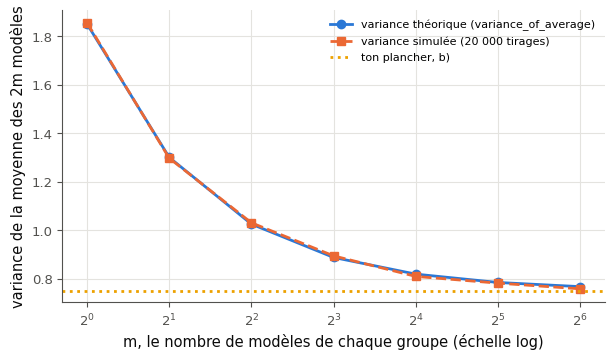

In [19]:
def simulate_mean_variance(m, n_draws, rng):
    """The empirical variance of the mean of the 2m models (m of group A, then m of group B) over n_draws draws: each
    draw takes one pair (Z_A, Z_B) of covariance COV_Z_13 and 2m independent own parts of variance OWN_13, all with
    the generator rng."""
    common = rng.multivariate_normal(np.zeros(2), COV_Z_13, size=n_draws)      # (n_draws, 2): Z_A and Z_B
    own = rng.normal(0.0, math.sqrt(OWN_13), size=(n_draws, 2 * m))            # a standard deviation, not a variance
    errors = np.repeat(common, m, axis=1) + own                                 # m models of A, then m of B
    return float(np.var(errors.mean(axis=1)))


def models_covariance(m):
    """The (2m, 2m) covariance matrix of the errors of the 2m models: m of group A, then m of group B."""
    common = np.kron(COV_Z_13, np.ones((m, m)))      # Cov(Z_g, Z_h) between a model of g and a model of h
    return common + OWN_13 * np.eye(2 * m)          # the own parts: on the diagonal only


start_13 = time.perf_counter()
rng_13 = np.random.default_rng(4331)
simulated_13 = [simulate_mean_variance(m, N_DRAWS_13, rng_13) for m in MS_13]
theoretical_13 = [ref_13.variance_of_average(models_covariance(m)) for m in MS_13]
answer_M14_13a = round(ref_13.variance_of_average(models_covariance(6)), 6)
answer_M14_13b = (VAR_A_13 + VAR_B_13 + 2 * COV_AB_13) / 4                # the variance of (Z_A + Z_B)/2
answer_M14_13c = all(abs(s / t - 1) < 0.05 for s, t in zip(simulated_13, theoretical_13))
answer_M14_13d = round(answer_M14_13b / theoretical_13[MS_13.index(32)], 4)
print("a)", answer_M14_13a, " b)", round(answer_M14_13b, 6), " c)", answer_M14_13c, " d)", answer_M14_13d,
      f" ({time.perf_counter() - start_13:.1f} s)")
for m, s, t in zip(MS_13, simulated_13, theoretical_13):
    print(f"m = {m:2d} : simulée {s:.4f}, théorique {t:.4f}, écart {100 * (s / t - 1):+.2f} %".replace(".", ","))
print("corrélation de deux modèles du groupe B :", round(VAR_B_13 / (VAR_B_13 + OWN_13), 4))
fig, ax = plt.subplots(figsize=(7.0, 3.8))
try:
    rng_fig_13 = np.random.default_rng(4331)
    simulated_13 = [simulate_mean_variance(m, N_DRAWS_13, rng_fig_13) for m in MS_13]
    theoretical_13 = [ref_13.variance_of_average(models_covariance(m)) for m in MS_13]
    ax.plot(MS_13, theoretical_13, "o-", color="C0", label="variance théorique (variance_of_average)")
    ax.plot(MS_13, simulated_13, "s--", color="C1", label="variance simulée (20 000 tirages)")
    try:
        floor_13 = float(Fraction(str(answer_M14_13b).replace(" ", ""))) if filled(answer_M14_13b) else None
    except (ValueError, ZeroDivisionError, NameError):
        floor_13 = None
    if floor_13 is not None:
        ax.axhline(floor_13, color="C3", ls=":", label="ton plancher, b)")
    ax.set_xscale("log", base=2)
    ax.set_xlabel("m, le nombre de modèles de chaque groupe (échelle log)")
    ax.set_ylabel("variance de la moyenne des 2m modèles")
    ax.legend(fontsize=8)
except BaseException:
    plt.close(fig)
    raise
plt.show()

In [20]:
from fractions import Fraction as Fr

va_13r, vb_13r, cab_13r, own_13r = Fr(6, 10), Fr(14, 10), Fr(5, 10), Fr(22, 10)
floor_13r = (va_13r + vb_13r + 2 * cab_13r) / 4


def var_13r(m):
    """The variance of the mean of m models of each group: the common part, then the own parts."""
    return floor_13r + own_13r / (2 * m)


wbm.record("M14.13a", float(var_13r(6)), decimals=6,
           mistakes={"Z_A et Z_B sont corrélées : leur covariance compte dans la part commune":
                         float(var_13r(6) - cab_13r / 2),
                     "la moyenne porte sur les 2m modèles des deux groupes": float(floor_13r + own_13r / 6),
                     "les modèles d'un même groupe partagent leur part commune : leurs covariances ne sont pas nulles":
                         float((va_13r + vb_13r + 2 * own_13r) / 24)})
wbm.record("M14.13b", float(floor_13r), decimals=6,
           mistakes={"Z_A et Z_B sont corrélées : leur covariance compte dans le plancher": float((va_13r + vb_13r) / 4),
                     "la part commune de la moyenne est (Z_A + Z_B)/2 : calcule sa variance":
                         float((va_13r + vb_13r) / 2)})
wbm.record("M14.13c", True,
           mistakes={"tes variances simulées s'écartent de plus de 5 % : chaque tirage prend UNE paire (Z_A, Z_B) pour "
                     "ses 2m modèles et 2m parts propres indépendantes ; rng.normal prend l'ÉCART-TYPE, la racine de la "
                     "variance": False})
wbm.record("M14.13d", float(floor_13r / var_13r(32)), decimals=4,
           mistakes={"d) demande la part du plancher DANS la variance, un nombre entre 0 et 1":
                         float(var_13r(32) / floor_13r),
                     "d) demande la part du PLANCHER, pas celle des parts propres": float(1 - floor_13r / var_13r(32))})

WBM_ANSWER {"coarse_any": {"0": ["eda6b6602552a9958c9e3d8544d24d9eef3b20d189597d87066a5ee6f9bd3491"], "1": ["78cb989785cda7539421109e7fe4751e00a945d05f87f4634ff08612782a19f6"]}, "coarser": {"2": ["fa86114e7444885d7dca2bc1cd358a065b7c94497390d06cc657146bd31b7b2b"], "3": ["0c71fc2dd0d5a7d153a91e457ed73cf70d678386a9f9ae9fa121c64bd17d1f50"], "4": ["c36dca9a97bf184d8389abeae91e00d7d912f70e96ac32e512f58cdfe70978af"]}, "decimals": 6, "hash": "07e45ed634d3017eb212f3d26c4daa9017ca09df7f7bae338b67da291b9c71f7", "hash_coarse": "28a0547d8f968e1508810df8b39565f3509725129f34cae574394c247ba6e15e", "id": "M14.13a", "kind": "float", "magnitude": -1, "mistakes": {"702ce6e71e70cd6060974cd4b784a6f4eeb6abe5d3920ac17eb3f8a4460eea53": "les modèles d'un même groupe partagent leur part commune : leurs covariances ne sont pas nulles", "8889be8e478021702cbad5689e65d27908301aea0559a593681b765f80d85aca": "Z_A et Z_B sont corrélées : leur covariance compte dans la part commune", "ec03a8c12f8ca8243692c45400ddaaf3de7

💡 La moyenne des $2m$ erreurs vaut $\frac{Z_A + Z_B}{2} + \frac{1}{2m}\sum_i E_i$ : sa variance est $\frac{0{,}6 + 1{,}4 + 2 \times 0{,}5}{4} + \frac{2{,}2}{2m} = 0{,}75 + \frac{1{,}1}{m}$. a) Pour $m = 6$, $\frac{14}{15} \approx 0{,}933333$. b) Le plancher $\frac{3}{4} = 0{,}75$ : le terme des parts propres, $\frac{1{,}1}{m}$, tend vers 0, celui des parts communes reste. c) Les écarts mesurés restent sous 1,2 % (l'écart-type relatif $\sqrt{2/20\,000} \approx 1\,\%$ prévoit cet ordre de grandeur). d) Pour $m = 32$ (64 modèles), la variance vaut $0{,}784375$, dont le plancher fait $\frac{240}{251} \approx 0{,}9562$ : plus de 95 % de ce qui reste vient des parts communes, et doubler encore le nombre de modèles ne gagne qu'environ $0{,}017$. Deux modèles du groupe B ont la corrélation $\frac{1{,}4}{1{,}4 + 2{,}2} \approx 0{,}389$. Avec $\operatorname{Cov}(Z_A, Z_B) < 0$, les deux parts communes se compenseraient en partie, et le plancher $\frac{V_A + V_B + 2\operatorname{Cov}}{4}$ baisserait : des modèles dont les erreurs communes vont en sens opposés se corrigent mutuellement.

### Ex M14.14 — Les poids exponentiels au fil des tours : quel expert domine, selon le learning rate 🎨 ★ ⏱️ 15 min
**Objectif :** tracer les poids de Hedge au fil des tours pour plusieurs learning rates, et voir comment η règle la vitesse et les à-coups avec lesquels ils suivent le meilleur expert.  
**Prérequis :** fiche §4 ; Ex M14.12 · **Parcours :** C

Cinq experts, 80 tours : la cellule fournie tire leurs losses dans $[0, 1]$ (graine 4334). L'expert 3 est le meilleur en moyenne, mais il commence mal. Écris `draw_hedge(axes, losses, etas)`, qui, pour chaque learning rate de `etas`, dessine dans l'axe correspondant de `axes` (sans en ouvrir d'autre) :
- le poids de chaque expert au fil des tours, une courbe (`ax.plot`) ou une aire empilée (`ax.stackplot`) par expert, avec les $T + 1 = 81$ lignes de `hedge_weights(losses, eta)` (la tienne, `mymath.ensembles.hedge_weights`, ou celle de la référence, `ref_14.hedge_weights`) ;
- un titre qui donne la valeur de $\eta$, une légende et des noms d'axes.

La cellule de vérification appelle ta fonction avec trois axes, pour $\eta$ = 0,15, 0,6 et 3, contrôle que les dessins sont dans les axes reçus, qu'il y a une courbe (ou une aire) par expert, que les valeurs tracées sont les bons poids, et que chaque titre donne $\eta$, puis affiche ta figure.

Dans ta copie : pour chaque $\eta$, quel expert domine à la fin, et à partir de quel tour son poids dépasse-t-il 0,5 pour de bon ? Que font les poids pendant les vingt premiers tours avec $\eta = 3$, et pourquoi ces à-coups coûtent-ils au regret (fiche §4, le second terme de la borne) ? Avec $\eta = 0{,}15$, l'expert 3 a-t-il assez de poids à la fin ? Lequel des trois choisirais-tu pour ces 80 tours, et que dit la formule $\eta = \sqrt{8\ln K/T}$ ?

In [21]:
rng_14 = np.random.default_rng(4334)
MEANS_14 = np.array([0.46, 0.52, 0.34, 0.6, 0.49])                       # the mean loss of each of the 5 experts
LOSSES_14 = np.clip(MEANS_14 + rng_14.normal(0.0, 0.2, size=(80, 5)), 0.0, 1.0)  # 80 rounds
LOSSES_14[:12, 2] = np.clip(LOSSES_14[:12, 2] + 0.3, 0.0, 1.0)            # expert 3 starts badly
LOSSES_14 = np.round(LOSSES_14, 2)
ETAS_14 = (0.15, 0.6, 3.0)
ref_14 = wbm.load_mymath("ref", alias="mymath_ref").ensembles

moyennes des losses : [0.442, 0.52, 0.381, 0.613, 0.529]
en tête avant chaque tour : 155255112221522222322222333333333333333333333333333333333333333333333333333333333
η = 0,15 : le poids de l'expert 3 dépasse 0,5 pour de bon à la ligne 68 ; poids finaux [0.253, 0.099, 0.527, 0.032, 0.089] ; plus grand saut d'un tour : 0.025
η = 0,6 : le poids de l'expert 3 dépasse 0,5 pour de bon à la ligne 36 ; poids finaux [0.051, 0.001, 0.947, 0.0, 0.001] ; plus grand saut d'un tour : 0.085
η = 3 : le poids de l'expert 3 dépasse 0,5 pour de bon à la ligne 24 ; poids finaux [0.0, 0.0, 1.0, 0.0, 0.0] ; plus grand saut d'un tour : 0.361
η = √(8 ln K / T) pour K = 5, T = 80 : 0.401
✅ draw_hedge dessine dans les axes reçus
✅ η = 0,15 : une courbe par expert, avec les bons poids
✅ η = 0,15 : le titre donne η
✅ η = 0,6 : une courbe par expert, avec les bons poids
✅ η = 0,6 : le titre donne η
✅ η = 3 : une courbe par expert, avec les bons poids
✅ η = 3 : le titre donne η


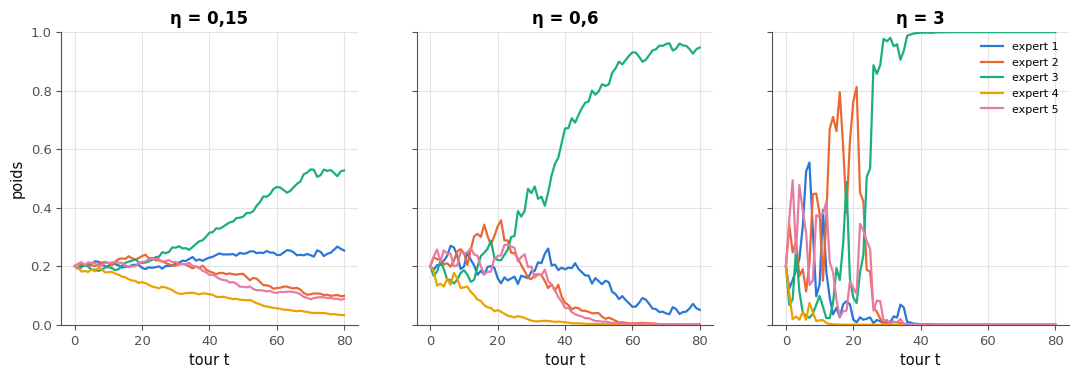

✅ Ex M14.14 : la figure est dans les axes reçus, avec les bons poids et un titre par axe.


In [22]:
def draw_hedge(axes, losses, etas):
    """In each axes received (one per learning rate of etas, and no other): the weight of each expert before each
    round and after the last one, from hedge_weights, with a title that gives eta."""
    losses = np.asarray(losses, dtype=float)
    rounds = np.arange(losses.shape[0] + 1)
    for ax, eta in zip(axes, etas):
        weights = ref_14.hedge_weights(losses, eta)
        for k in range(weights.shape[1]):
            ax.plot(rounds, weights[:, k], lw=1.6, label=f"expert {k + 1}")
        ax.set_title(f"η = {eta:g}".replace(".", ","))
        ax.set_xlabel("tour t")
        ax.set_ylim(0.0, 1.0)
    axes[0].set_ylabel("poids")
    axes[-1].legend(fontsize=8)


cumulative_14 = np.vstack([np.zeros(5), np.cumsum(LOSSES_14, axis=0)])
print("moyennes des losses :", LOSSES_14.mean(axis=0).round(3).tolist())
print("en tête avant chaque tour :", "".join(str(k + 1) for k in cumulative_14.argmin(axis=1)))
for eta in ETAS_14:
    w_14 = ref_14.hedge_weights(LOSSES_14, eta)
    good = next(t for t in range(len(w_14)) if np.all(w_14[t:, 2] > 0.5))
    print(f"η = {eta:g}".replace(".", ",") + f" : le poids de l'expert 3 dépasse 0,5 pour de bon à la ligne {good} ; "
          f"poids finaux {np.round(w_14[-1], 3).tolist()} ; plus grand saut d'un tour : "
          f"{np.abs(np.diff(w_14, axis=0)).max():.3f}")
print("η = √(8 ln K / T) pour K = 5, T = 80 :", round(math.sqrt(8 * math.log(5) / 80), 3))


with checked("M14.14"):
    results_14 = []

    def report_14(ok, success, failure):
        results_14.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def drawn_series_14(ax, rows):
        """The series of `rows` values drawn in ax: the y data of its lines, else the heights of its filled areas."""
        series = [np.asarray(line.get_ydata(), dtype=float) for line in ax.lines if len(line.get_ydata()) == rows]
        if series:
            return series
        for collection in ax.collections:
            for path in collection.get_paths():
                points = np.asarray(path.vertices, dtype=float)
                xs = np.unique(np.round(points[:, 0], 9))
                if len(xs) == rows:
                    series.append(np.array([np.ptp(points[np.isclose(points[:, 0], x), 1]) for x in xs]))
        return series

    fig, axes = plt.subplots(1, len(ETAS_14), figsize=(13.0, 3.8), sharey=True)
    try:
        opened_14 = drawn(draw_hedge, axes, LOSSES_14, ETAS_14)
    except BaseException:
        plt.close(fig)
        raise
    report_14(not opened_14 and all(ax.lines or ax.collections for ax in axes), "draw_hedge dessine dans les axes reçus",
              "draw_hedge doit dessiner dans chacun des axes reçus, sans ouvrir de figure (ni plt.figure ni plt.subplots)")
    for ax, eta in zip(axes, ETAS_14):
        want = ref_14.hedge_weights(LOSSES_14, eta)
        series = drawn_series_14(ax, want.shape[0])
        found = sum(any(np.allclose(s, want[:, k], rtol=0, atol=1e-6) for s in series) for k in range(want.shape[1]))
        shown = f"{eta:g}".replace(".", ",")
        report_14(found == want.shape[1], f"η = {shown} : une courbe par expert, avec les bons poids",
                  f"η = {shown} : je trouve {found} expert(s) sur {want.shape[1]} dont les {want.shape[0]} poids (avant "
                  f"chaque tour, puis après le dernier) sont tracés ; trace chaque colonne de hedge_weights(losses, eta), "
                  f"une courbe ou une aire empilée par expert")
        title = ax.get_title()
        report_14(f"{eta:g}" in title or shown in title, f"η = {shown} : le titre donne η",
                  f"le titre de l'axe de η = {shown} doit donner la valeur de η (il vaut « {title} »)")
    plt.show()
    verdict("M14.14", all(results_14), "la figure est dans les axes reçus, avec les bons poids et un titre par axe.",
            "relis les lignes ❌ ci-dessus.")

💡 L'expert 3 (loss moyenne $\approx 0{,}55$ sur les douze premiers tours, $\approx 0{,}35$ ensuite) prend la tête des losses cumulées à la ligne 24 et la garde ; avant, elle passe des experts 1 et 5 à l'expert 2. Avec $\eta = 3$, les poids suivent le meneur presque sans retard : son poids dépasse 0,5 dès la ligne 24 et finit à $\approx 1$, mais pendant les vingt premiers tours tout le poids saute d'un expert à l'autre (jusqu'à 0,36 en un tour), et chaque saut fait payer la loss d'un expert qui vient de perdre la tête : c'est le terme $\frac{\eta T}{8}$ de la borne. Avec $\eta = 0{,}15$, les poids restent répartis : l'expert 3 ne passe 0,5 qu'à la ligne 68 et finit à $0{,}53$, trop prudent. $\eta = 0{,}6$ (passage à la ligne 36, $0{,}95$ à la fin) est proche de $\sqrt{8\ln 5/80} \approx 0{,}40$, le $\eta$ qui équilibre les deux termes de la borne pour 80 tours.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1, §2 et §4. Quatre erreurs à trouver dans un résumé de calculs, un test de propriétés de la borne de Chernoff, puis Hedge sans connaître l'horizon.

### Ex M14.15 — Chasse à l'erreur : P(X ≥ k) calculée comme P(X > k), des covariances oubliées, des poids non renormalisés 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans un résumé de calculs les erreurs classiques d'une queue binomiale, d'une borne de Chernoff, d'une variance de moyenne et des poids de Hedge, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §1, §2 et §4 · **Parcours :** C

Une collègue résume trois calculs (la cellule fournie) : la fiabilité d'une grappe de 16 serveurs qui fonctionne tant qu'au moins 13 sont en marche, chacun en marche avec la probabilité 0,93, indépendamment des autres ($X$, le nombre de serveurs en marche, suit la loi $\mathcal{B}(16 ;\ 0{,}93)$) ; la variance de la moyenne des erreurs de quatre modèles, de matrice de covariance `S_15` ; et les poids de Hedge de quatre experts, de losses cumulées `CUM_15`, avec $\eta = 0{,}35$. La fonction `kl_15(u, v)` rend $\mathrm{KL}(u \Vert v)$. Sept lignes portent une lettre et un commentaire qui dit ce qu'elles doivent calculer. Quatre lignes ne font pas ce que dit leur commentaire. **Sans exécuter son code**, trouve-les.

```python
n, k, p = N_15, 13, P_15                             # the cluster works while at least k = 13 servers are up
works = binom.sf(k, n, p)                                       # (A) P(X ≥ k): the probability that the cluster works
full = binom.sf(15 - 1, n, p)                                   # (B) P(X ≥ 15): at least 15 servers up
chernoff = np.exp(-n * kl_15(1 - p, A_15))                      # (C) the Chernoff bound on P(at least n·A_15 servers down)
var_plain = np.mean(np.diag(S_15)) / len(S_15)                  # (D) the variance of the plain mean of the 4 models
var_weighted = W_15 @ S_15 @ W_15                               # (E) the variance of their mean with the weights W_15
shifted = CUM_15 - CUM_15.min()                                 # (F) the cumulative losses minus the smallest one
weights = np.exp(-ETA_15 * shifted)                             # (G) the Hedge weights, a law on the 4 experts
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) la bonne valeur de `works` (4 décimales) ;
- c) la bonne valeur de `chernoff` (4 décimales) ;
- d) la bonne valeur de `var_plain` (4 décimales) ;
- e) la bonne valeur de `weights` (une liste de 4 nombres, 4 décimales).

Pour b) à e), écris le code corrigé dans la cellule (c'est permis : seule la recherche des lignes fausses se fait sans exécuter).

In [23]:
def kl_15(u, v):
    """KL(u ‖ v) between the Bernoulli laws of parameters u and v, in nats (0 < u, v < 1)."""
    return u * np.log(u / v) + (1 - u) * np.log((1 - u) / (1 - v))


N_15, P_15 = 16, 0.93            # 16 servers, each up with probability 0.93, independently of the others
A_15 = 0.25                      # an event: at least 16 × 0.25 = 4 servers down
S_15 = np.array([[1.5, 0.6, -0.3, 0.4],
                 [0.6, 2.2, 0.5, -0.2],
                 [-0.3, 0.5, 0.9, 0.1],
                 [0.4, -0.2, 0.1, 3.2]])     # the covariance matrix of the errors of 4 models
W_15 = np.array([0.3, 0.15, 0.4, 0.15])     # weights of sum 1
CUM_15 = np.array([12.5, 9.0, 10.5, 14.0])  # the cumulative losses of 4 experts
ETA_15 = 0.35

In [24]:
answer_M14_15a = "ACDG"
n_15, k_15, p_15 = N_15, 13, P_15
works_15 = binom.sf(k_15 - 1, n_15, p_15)                                # (A) P(X ≥ k) = P(X > k − 1)
chernoff_15 = np.exp(-n_15 * kl_15(A_15, 1 - p_15))                      # (C) KL(a ‖ p): the event first
var_plain_15 = np.ones(4) @ S_15 @ np.ones(4) / 16                       # (D) every cell, covariances included
weights_15 = np.exp(-ETA_15 * (CUM_15 - CUM_15.min()))
weights_15 = weights_15 / weights_15.sum()                               # (G) a law: divide by the sum
answer_M14_15b, answer_M14_15c = round(float(works_15), 4), round(float(chernoff_15), 4)
answer_M14_15d, answer_M14_15e = round(float(var_plain_15), 4), np.round(weights_15, 4).tolist()
print(answer_M14_15a, answer_M14_15b, answer_M14_15c, answer_M14_15d, answer_M14_15e)
print("lignes de la collègue : (A)", round(float(binom.sf(13, 16, P_15)), 4),
      " (C)", round(float(np.exp(-16 * kl_15(1 - P_15, A_15))), 4),
      " (D)", round(float(np.mean(np.diag(S_15)) / 4), 4),
      " (G) somme des poids :", round(float(np.exp(-ETA_15 * (CUM_15 - CUM_15.min())).sum()), 4))
print("P(au moins 4 serveurs en panne), exacte :", round(float(binom.sf(3, 16, 1 - P_15)), 4))

ACDG 0.9779 0.0812 0.625 [0.1427, 0.4857, 0.2873, 0.0844]
lignes de la collègue : (A) 0.9031  (C) 0.1695  (D) 0.4875  (G) somme des poids : 2.0591
P(au moins 4 serveurs en panne), exacte : 0.0221


In [25]:
wbm.record("M14.15a", "ACDG",
           mistakes={"il manque une ligne fautive : relis ce que rend binom.sf(m, n, p) pour un événement « au moins k »": "CDG",
                     "il manque une ligne fautive : relis l'ordre des deux arguments de la divergence dans la borne de Chernoff": "ADG",
                     "il manque une ligne fautive : relis ce que compte la variance d'une moyenne de variables corrélées": "ACG",
                     "il manque une ligne fautive : relis ce qu'il faut pour qu'une liste de poids soit une loi sur les experts": "ACD",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCDG", "ACDEG", "ACDFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis ce que rend binom.sf(m, n, p) pour un événement « au moins k »": {"BCDG", "CDEG", "CDFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis l'ordre des deux arguments de la divergence dans la borne de Chernoff": {"ABDG", "ADEG", "ADFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis ce que compte la variance d'une moyenne de variables corrélées": {"ABCG", "ACEG", "ACFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis ce qu'il faut pour qu'une liste de poids soit une loi sur les experts": {"ABCD", "ACDE", "ACDF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "D", "G", "AC", "AD", "AG", "CD", "CG", "DG"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "E", "F", "AB", "AE", "AF", "BC", "BD", "BE", "BF", "BG", "CE", "CF", "DE", "DF", "EF", "EG", "FG", "ABC", "ABD", "ABE", "ABF", "ABG", "ACE", "ACF", "ADE", "ADF", "AEF", "AEG", "AFG", "BCD", "BCE", "BCF", "BCG", "BDE", "BDF", "BDG", "BEF", "BEG", "BFG", "CDE", "CDF", "CEF", "CEG", "CFG", "DEF", "DEG", "DFG", "EFG", "ABCE", "ABCF", "ABDE", "ABDF", "ABEF", "ABEG", "ABFG", "ACEF", "ADEF", "AEFG", "BCDE", "BCDF", "BCEF", "BCEG", "BCFG", "BDEF", "BDEG", "BDFG", "BEFG", "CDEF", "CEFG", "DEFG", "ABCDE", "ABCDF", "ABCEF", "ABCEG", "ABCFG", "ABDEF", "ABDEG", "ABDFG", "ABEFG", "ACDEF", "ACEFG", "ADEFG", "BCDEF", "BCDEG", "BCDFG", "BCEFG", "BDEFG", "CDEFG", "ABCDEF", "ABCEFG", "ABDEFG", "BCDEFG"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEG", "ABCDFG", "ACDEFG", "ABCDEFG"}})


def kl_15r(u, v):
    """KL(u ‖ v) between Bernoulli laws, in nats."""
    return u * math.log(u / v) + (1 - u) * math.log((1 - u) / (1 - v))


def at_least_15r(k):
    """P(X ≥ k) for X of law B(16 ; 0.93), as a sum."""
    return sum(math.comb(16, j) * 0.93 ** j * 0.07 ** (16 - j) for j in range(k, 17))


wbm.record("M14.15b", at_least_15r(13), decimals=4,
           mistakes={"« au moins 13 » compte aussi X = 13 : binom.sf(m, n, p) rend P(X > m)": at_least_15r(14)})
wbm.record("M14.15c", math.exp(-16 * kl_15r(0.25, 0.07)), decimals=4,
           mistakes={"KL(a ‖ p) : d'abord la proportion de l'événement, puis le paramètre de la loi":
                         math.exp(-16 * kl_15r(0.07, 0.25))})
s_15r = np.array([[1.5, 0.6, -0.3, 0.4], [0.6, 2.2, 0.5, -0.2], [-0.3, 0.5, 0.9, 0.1], [0.4, -0.2, 0.1, 3.2]])
wbm.record("M14.15d", float(s_15r.sum()) / 16, decimals=4,
           mistakes={"la variance de la moyenne compte toutes les cases de S_15, covariances comprises":
                         float(np.trace(s_15r)) / 16})
raw_15r = np.exp(-0.35 * (np.array([12.5, 9.0, 10.5, 14.0]) - 9.0))
up_15r = np.exp(0.35 * (np.array([12.5, 9.0, 10.5, 14.0]) - 14.0))
wbm.record("M14.15e", (raw_15r / raw_15r.sum()).tolist(), decimals=4,
           mistakes={"une loi sur les experts : divise les poids par leur somme": raw_15r.tolist(),
                     "e^(−ηL) : une grande loss cumulée, un PETIT poids": (up_15r / up_15r.sum()).tolist()})

WBM_ANSWER {"hash": "981404bf0d7aa046483bf54bd0d404ad8bcf2b1c378271659b2ddcf6999920f7", "id": "M14.15a", "kind": "str", "mistakes": {"0237cade63fad6753796c9668731345122a2ba4c5b2fc525048365b9e8a1393d": "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis ce que compte la variance d'une moyenne de variables corrélées", "045ab34eda42f38479af060b3442c2c591ba04ce71777cbbc241c651ca0e7b86": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "057dbb8a9d5fbb511c9e1552dd72676438e6094a09e95414bccd8a7905826120": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0a60b69e654db73588596aa76b9dd1a2f8500bdeba8666234e530f9a40f219d6": "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis ce que compte la variance d'une moyenne de variables corrélées", "0cdd48f81daed5be7c97f8d83b46db145b2d2959b76d34b229be68dc

**Après la vérification**, dans ta copie : pour chaque ligne fausse, que calcule-t-elle exactement, et comment la corriger ? Laquelle sous-estime la fiabilité de la grappe, et laquelle donne un nombre plausible sans aucun signal ? Pourquoi les lignes (B) et (F), qui ressemblent à des lignes fausses, sont-elles justes ? La borne de (C) corrigée est-elle proche de la probabilité exacte qu'au moins 4 serveurs soient en panne, et pourquoi ?

💡 (A) `binom.sf(m, n, p)` rend $P(X > m)$ : la ligne calcule $P(X \ge 14) \approx 0{,}9031$ au lieu de $P(X \ge 13) \approx 0{,}9779$, et sous-estime la fiabilité ; (B), `binom.sf(15 - 1, n, p)`, est juste. (C) La borne de Chernoff de $P(F \ge 16 \times 0{,}25)$, pour $F = 16 - X$ de loi $\mathcal{B}(16 ;\ 0{,}07)$, est $e^{-16\,\mathrm{KL}(0{,}25 \Vert 0{,}07)} \approx 0{,}0812$ : la proportion de l'événement d'abord ; la ligne inverse les arguments et trouve $0{,}1695$. La probabilité exacte vaut $\approx 0{,}0221$ : pour $n = 16$, la borne reste près de quatre fois au-dessus. (D) oublie les covariances : $\frac{7{,}8}{16} = 0{,}4875$ au lieu de $\frac{10}{16} = 0{,}625$, un nombre plausible sans aucun signal. (E) $\mathbf{w}^\top\mathbf{S}\mathbf{w}$ est juste, et (F) retranche le minimum, ce qui ne change pas les poids une fois normalisés. (G) ne divise pas par la somme : les « poids » $(0{,}2938 ;\ 1 ;\ 0{,}5916 ;\ 0{,}1738)$ somment à $2{,}06$ ; normalisés, $(0{,}1427 ;\ 0{,}4857 ;\ 0{,}2873 ;\ 0{,}0844)$.

### Ex M14.16 — Un test qui vérifie que la borne de Chernoff majore la queue exacte de `scipy.stats`, sur une grille de n, p et a 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriétés d'une borne, sur une grille qui contient les cas extrêmes, et vérifier qu'il attrape des bornes fausses.  
**Prérequis :** fiche §1 ; Ex M14.11 · **Parcours :** C

Une borne se teste par ses **propriétés**. Écris `test_chernoff_dominates(bound)`, une fonction de test dans le style de pytest (des `assert` avec un message qui dit le cas), qui reçoit une fonction `bound(n, p, a)` et vérifie, sur une grille de $n$, $p$ et $a$ de ton choix (au moins 100 cas, $a$ jusqu'à 1, des $p$ près de 0 et près de 1) :
- que `bound(n, p, a)` est dans $[0, 1]$ ;
- qu'elle majore la queue exacte $P(X \ge na)$ de la loi $\mathcal{B}(n, p)$, calculée par `binom.sf(k - 1, n, p)` avec $k = \lceil na \rceil$ (attention aux flottants : `50 * 0.14` vaut `7.000000000000001`) ;
- que, pour $a > p$, elle reste sous la borne de Hoeffding $e^{-2n(a - p)^2}$ (fiche §1 : l'inégalité de Pinsker) ;
- que, pour $a > p$, elle ne croît pas avec $n$ (compare par exemple `bound(n, p, a)` et `bound(2 * n, p, a)`).

Prévois une petite tolérance (`1e-12`) dans chaque comparaison. La vérification appelle ton test sur la vraie borne, `ref_16.chernoff_bound`, où il doit **passer**, et compte les cas de ta grille ; puis sur les quatre fausses bornes de la cellule fournie, où il doit **échouer** : `bound_half`, la moitié de la borne ; `bound_squared`, $e^{-2n\,\mathrm{KL}(a \Vert p)}$ ; `bound_fixed_lambda`, l'inégalité de Markov appliquée à $e^{\lambda X}$ avec $\lambda = 1$ au lieu du meilleur $\lambda$ ; `bound_markov`, la borne de Markov $\min(1, p/a)$.

Dans ta copie : quelle propriété attrape chacune des quatre fausses bornes, et sur quel cas de ta grille ? Deux d'entre elles sont de **vraies** bornes de la queue, toujours au-dessus d'elle : lesquelles, et pourquoi ton test les refuse-t-il quand même ? Pourquoi `bound_fixed_lambda` peut-elle rendre plus que 1 ?

In [26]:
ref_16 = wbm.load_mymath("ref", alias="mymath_ref").ensembles


def bound_half(n, p, a):
    """A wrong bound: half the Chernoff bound."""
    return 0.5 * ref_16.chernoff_bound(n, p, a)


def bound_squared(n, p, a):
    """A wrong bound: exp(-2 n KL(a ‖ p)), the square of the Chernoff bound."""
    return ref_16.chernoff_bound(n, p, a) ** 2


def bound_fixed_lambda(n, p, a):
    """Markov's inequality on e^(λX) with λ = 1 instead of the best λ: e^(-n a) (1 - p + p e)^n (capped at e^700)."""
    return math.exp(min(700.0, n * (math.log(1 - p + p * math.e) - a)))


def bound_markov(n, p, a):
    """Markov's bound min(1, p / a) on P(X ≥ n a) (1 for a = 0)."""
    return min(1.0, p / a) if a > 0 else 1.0


WRONG_16 = {"bound_half (la moitié de la borne)": bound_half,
            "bound_squared (e^(−2n KL))": bound_squared,
            "bound_fixed_lambda (Markov sur e^X, λ = 1)": bound_fixed_lambda,
            "bound_markov (min(1, p/a))": bound_markov}

In [27]:
def test_chernoff_dominates(bound):
    """bound(n, p, a) is in [0, 1], above the exact tail P(X >= n a) of B(n, p), below Hoeffding's bound for a > p,
    and does not increase with n for a > p: on a grid of n, p and a."""
    cases = 0
    for n in (1, 3, 9, 27, 81, 243):
        for p in (0.01, 0.07, 0.32, 0.57, 0.85, 0.97):         # rare events near 0 and near 1
            for a in np.linspace(0.0, 1.0, 11):
                a = float(a)
                value = bound(n, p, a)
                assert 0.0 <= value <= 1.0, f"n = {n}, p = {p}, a = {a}: bound {value} outside [0, 1]"
                tail = float(binom.sf(math.ceil(n * a - 1e-9) - 1, n, p))   # P(X >= n a), n * a seen as a float
                assert value >= tail - 1e-12, f"n = {n}, p = {p}, a = {a}: bound {value} below the exact tail {tail}"
                if a > p:
                    hoeffding = math.exp(-2 * n * (a - p) ** 2)
                    assert value <= hoeffding + 1e-12, (f"n = {n}, p = {p}, a = {a}: bound {value} above "
                                                        f"Hoeffding's {hoeffding}")
                    assert bound(2 * n, p, a) <= value + 1e-12, f"n = {n}, p = {p}, a = {a}: the bound grows with n"
                cases += 1
    assert cases >= 100, f"only {cases} cases"


for label, wrong in WRONG_16.items():                       # which property catches each wrong bound, and where
    try:
        test_chernoff_dominates(wrong)
        print(label, ": not caught")
    except AssertionError as exc:
        print(label, ":", exc)


with checked("M14.16"):
    if len(inspect.signature(test_chernoff_dominates).parameters) != 1:
        raise TypeError("ton test prend un seul argument, la borne à tester : def test_chernoff_dominates(bound)")
    results_16, calls_16 = [], []

    def report_16(ok, success, failure):
        results_16.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def recorded_16(n, p, a):
        """The true bound, which records the cases of your grid."""
        calls_16.append((n, float(p), float(a)))
        return ref_16.chernoff_bound(n, p, a)

    try:
        test_chernoff_dominates(recorded_16)          # your test on the true bound: ⏳ while it is not written
        why_16 = ""
    except AssertionError as exc:
        why_16 = str(exc)[:200] or "un assert sans message"
    report_16(not why_16, "ton test passe sur la vraie borne de Chernoff",
              f"ton test échoue sur la vraie borne de Chernoff : il refuse une borne juste ({why_16})")
    cases_16 = set(calls_16)
    report_16(len(cases_16) >= 100, f"ta grille compte {len(cases_16)} cas différents",
              f"ta grille ne compte que {len(cases_16)} cas différents : il en faut au moins 100")
    report_16(bool(cases_16) and max(a for _, _, a in cases_16) >= 1 - 1e-9, "a va jusqu'à 1",
              "ta grille doit aller jusqu'à a = 1 (le cas où 0 ln 0 compte pour 0)")
    report_16(bool(cases_16) and min(p for _, p, _ in cases_16) <= 0.05 and max(p for _, p, _ in cases_16) >= 0.95,
              "p va près de 0 et près de 1",
              "ta grille doit contenir des p près de 0 (au plus 0,05) et près de 1 (au moins 0,95) : les événements rares")
    hints_16 = {"bound_half": "compare-la à la queue exacte, aussi pour a ≤ p et pour a = 1",
                "bound_squared": "compare-la à la queue exacte, aussi pour de petits n",
                "bound_fixed_lambda": "vérifie que la borne reste dans [0, 1], aussi pour a ≤ p",
                "bound_markov": "compare-la à la borne de Hoeffding, pour a > p et de grands n"}
    for label_16, wrong_16 in WRONG_16.items():
        try:
            test_chernoff_dominates(wrong_16)
            report_16(False, "", f"ton test passe sur {label_16} : il ne la voit pas ; "
                                 f"{hints_16[wrong_16.__name__]}")
        except AssertionError:
            report_16(True, f"ton test échoue sur {label_16}", "")
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001 - a crash is not a failed assert
            report_16(False, "", f"ton test plante sur {label_16} ({type(exc).__name__} : {str(exc)[:100]}) au lieu "
                                 "d'échouer sur un assert")
    verdict("M14.16", all(results_16), "ton test accepte la vraie borne, couvre la grille demandée et attrape les "
                                       "quatre fausses bornes.", "relis les lignes ❌ ci-dessus.")

bound_half (la moitié de la borne) : n = 1, p = 0.01, a = 0.0: bound 0.5 below the exact tail 1.0
bound_squared (e^(−2n KL)) : n = 1, p = 0.01, a = 0.7000000000000001: bound 0.005345287978823257 below the exact tail 0.01
bound_fixed_lambda (Markov sur e^X, λ = 1) : n = 1, p = 0.01, a = 0.0: bound 1.0171828182845903 outside [0, 1]
bound_markov (min(1, p/a)) : n = 3, p = 0.01, a = 0.9: bound 0.011111111111111112 above Hoeffding's 0.008629230012995072
✅ ton test passe sur la vraie borne de Chernoff
✅ ta grille compte 606 cas différents
✅ a va jusqu'à 1
✅ p va près de 0 et près de 1
✅ ton test échoue sur bound_half (la moitié de la borne)
✅ ton test échoue sur bound_squared (e^(−2n KL))
✅ ton test échoue sur bound_fixed_lambda (Markov sur e^X, λ = 1)
✅ ton test échoue sur bound_markov (min(1, p/a))
✅ Ex M14.16 : ton test accepte la vraie borne, couvre la grille demandée et attrape les quatre fausses bornes.


💡 `bound_half` passe sous la queue exacte dès qu'elle est proche de la borne : pour $a \le p$ (la vraie borne vaut 1, la moitié 0,5 alors que la queue vaut presque 1) et pour $a = 1$, où la borne est exacte, $p^n$. `bound_squared` passe sous la queue pour $n = 1$, $p = 0{,}01$, $a = 0{,}7$ : $0{,}0053 < 0{,}01$. `bound_fixed_lambda` et `bound_markov` sont de vraies bornes (Markov vaut pour tout $\lambda > 0$, et pour $X$ lui-même), mais pas celles que demande le contrat : la première rend $(1 - p + pe)^n e^{-na} > 1$ dès que $a$ est petit (avec $a = 0$, $(1 + p(e - 1))^n > 1$), la seconde ne décroît pas avec $n$ et passe au-dessus de Hoeffding : pour $n = 3$, $p = 0{,}01$, $a = 0{,}9$, $\frac{0{,}01}{0{,}9} \approx 0{,}0111 > e^{-6 \times 0{,}89^2} \approx 0{,}0086$. Une grille utile contient des cas extrêmes : $a = 1$, des $p$ près de 0 et de 1, de petits et de grands $n$.

### Ex M14.17 — Défi : suivre le meilleur de dix experts avec Hedge sans connaître l'horizon, un regret sous la borne théorique sur 1 000 tours 🏆 ★★★ ⏱️ 25 min
**Objectif :** régler le learning rate de Hedge sans connaître l'horizon, pour garder un regret sous la borne théorique à tout moment, sur des suites de losses variées.  
**Prérequis :** fiche §4 ; Ex M14.12 et M14.14 · **Parcours :** C

Hedge avec $\eta = \sqrt{8\ln K/T}$ demande l'horizon $T$. Ici, tu ne le connais pas : les tours arrivent un à un, et ton regret est mesuré **à tout moment**, $R_t = \sum_{s \le t} \mathbf{w}_s \cdot \boldsymbol{\ell}_s - \min_k L_{t+1}[k]$.

**L'objectif** : écrire une classe `AnytimeHedge(K)`, pour $K$ experts, avec deux méthodes :
- `weights()` rend ta loi actuelle sur les experts : un tableau de $K$ nombres positifs ou nuls, de somme 1 ;
- `update(losses)` reçoit les losses du tour, un vecteur de $K$ nombres dans $[0, 1]$.

La vérification joue 1 000 tours sur trois suites de losses de 10 experts (cellule fournie, graines fixes) : `"stochastique"`, des losses aléatoires avec un meilleur expert net ; `"changement"`, où le meilleur expert change au 501ᵉ tour ; `"piège"`, où deux experts alternent en tête, ce qui fait échouer « suivre le meneur » (tout le poids sur l'expert de plus petite loss cumulée, $\eta = +\infty$). À chaque tour, elle lit `weights()`, ajoute $\mathbf{w}_t \cdot \boldsymbol{\ell}_t$ à ta loss, puis appelle `update(losses)`. Aux tours 50, 200 et 1 000, elle compare ton regret à la borne $\sqrt{2t\ln K} + \sqrt{\frac{\ln K}{8}}$ (fiche §4) : il doit être dessous à chacun des neuf points de contrôle. `hedge_weights`, `mymath`, `scipy`, `sklearn`, `sequence_17`, `SEQUENCES_17`, `T_17` et `CHECKPOINTS_17` sont interdits dans ta classe.

Essaie d'abord un $\eta$ constant (0,01, puis le meilleur pour $T = 1\,000$) et « suivre le meneur », pour voir où chacun échoue. Les indices de `04_indices.md` donnent des pistes, à ouvrir une à une.

Une dernière cellule enregistre si l'objectif est atteint.

Dans ta copie : où échouent $\eta = 0{,}01$, le meilleur $\eta$ constant pour $T = 1\,000$ et « suivre le meneur », et pourquoi ? Qu'as-tu choisi, et pourquoi ta méthode ne dépend-elle pas de $T$ ? Que vaut ton regret au tour 1 000 sur chaque suite, comparé à la borne ?

In [28]:
K_17, T_17, CHECKPOINTS_17 = 10, 1000, (50, 200, 1000)
SEQUENCES_17 = {"stochastique": 4337, "changement": 4338, "piège": 4339}     # the kind of each sequence, and its seed
ref_17 = wbm.load_mymath("ref", alias="mymath_ref").ensembles


def sequence_17(kind, seed):
    """The (T_17, K_17) losses, in [0, 1], of a sequence of the check."""
    rng = np.random.default_rng(seed)
    if kind == "stochastique":                       # 0/1 losses; expert 4 loses far less often than the others
        means = rng.uniform(0.6, 0.9, size=K_17)
        means[3] = 0.05
        return (rng.random((T_17, K_17)) < means).astype(float)
    if kind == "changement":                         # expert 2 is the best for 500 rounds, then expert 9
        means = rng.uniform(0.45, 0.75, size=(2, K_17))
        means[0, 1] = means[1, 8] = 0.2
        return np.clip(np.repeat(means, T_17 // 2, axis=0) + rng.normal(0.0, 0.15, size=(T_17, K_17)), 0.0, 1.0)
    losses = np.clip(0.75 + rng.normal(0.0, 0.1, size=(T_17, K_17)), 0.0, 1.0)   # "piège": experts 1 and 2 alternate
    rounds = np.arange(T_17)
    losses[:, 0] = np.where(rounds % 2 == 1, 0.0, 1.0)
    losses[:, 1] = np.where(rounds % 2 == 1, 1.0, 0.0)
    losses[0, :2] = (0.5, 0.0)
    return losses


def regret_bound_17(t):
    """The bound √(2t ln K) + √(ln K / 8) on the regret after t rounds, for K = K_17 experts."""
    return math.sqrt(2 * t * math.log(K_17)) + math.sqrt(math.log(K_17) / 8)

In [29]:
class AnytimeHedge:
    """Hedge on K experts without knowing the horizon: weights() is the current law on the experts (K non-negative
    numbers of sum 1), update(losses) adds the K losses of the round (numbers in [0, 1])."""

    def __init__(self, K):
        self.K = int(K)
        self.cumulative = np.zeros(self.K)          # L_t[k], the cumulative losses so far
        self.t = 1                                  # the round about to be played

    def weights(self):
        eta = math.sqrt(8 * math.log(self.K) / self.t)            # a learning rate that decreases with the round
        w = np.exp(-eta * (self.cumulative - self.cumulative.min()))
        return w / w.sum()

    def update(self, losses):
        self.cumulative = self.cumulative + np.asarray(losses, dtype=float)
        self.t += 1


class FixedHedge:
    """Hedge with a constant learning rate; math.inf follows the leader (ties share the weight)."""

    def __init__(self, K, eta):
        self.cumulative, self.eta = np.zeros(K), eta

    def weights(self):
        if math.isinf(self.eta):
            w = (self.cumulative == self.cumulative.min()).astype(float)
        else:
            w = np.exp(-self.eta * (self.cumulative - self.cumulative.min()))
        return w / w.sum()

    def update(self, losses):
        self.cumulative = self.cumulative + np.asarray(losses, dtype=float)


def regrets_17(agent, losses):
    """The regret of agent at the checkpoints."""
    total, cumulative, out = 0.0, np.zeros(losses.shape[1]), {}
    for t, row in enumerate(losses, start=1):
        total += float(agent.weights() @ row)
        cumulative += row
        agent.update(row)
        if t in CHECKPOINTS_17:
            out[t] = round(total - float(cumulative.min()), 1)
    return out


print("bornes :", {t: round(regret_bound_17(t), 1) for t in CHECKPOINTS_17})
strategies_17 = {"η = 0,01": lambda: FixedHedge(K_17, 0.01),
                 "η = √(8 ln K / 1000)": lambda: FixedHedge(K_17, math.sqrt(8 * math.log(K_17) / T_17)),
                 "suivre le meneur": lambda: FixedHedge(K_17, math.inf),
                 "η_t = √(8 ln K / t)": lambda: AnytimeHedge(K_17)}
for label, make in strategies_17.items():
    print(f"{label:>22} :", {name: regrets_17(make(), sequence_17(name, seed)) for name, seed in SEQUENCES_17.items()})

bornes : {50: 15.7, 200: 30.9, 1000: 68.4}
              η = 0,01 : {'stochastique': {50: 31.0, 200: 113.7, 1000: 229.8}, 'changement': {50: 18.2, 200: 65.3, 1000: 115.8}, 'piège': {50: 10.5, 200: 38.3, 1000: 133.5}}
  η = √(8 ln K / 1000) : {'stochastique': {50: 17.0, 200: 17.6, 1000: 17.6}, 'changement': {50: 13.5, 200: 17.2, 1000: 16.1}, 'piège': {50: 8.6, 200: 14.8, 1000: 28.4}}
      suivre le meneur : {'stochastique': {50: 1.6, 200: 1.6, 1000: 1.6}, 'changement': {50: 0.3, 200: 0.3, 1000: 0.7}, 'piège': {50: 25.2, 200: 100.2, 1000: 500.2}}


   η_t = √(8 ln K / t) : {'stochastique': {50: 1.9, 200: 1.9, 1000: 1.9}, 'changement': {50: 1.7, 200: 1.7, 1000: 0.8}, 'piège': {50: 6.8, 200: 14.4, 1000: 33.1}}


In [30]:
wbm.record("M14.17", True,
           mistakes={"l'objectif n'est pas atteint : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "aa985e6e9deaeb94bfa14424cdbd650f2a6ba60a04df00dc118d6b6e6b71bb1a", "id": "M14.17", "kind": "bool", "mistakes": {"19cb8666903dc4c6b4c8ed3d979db4493b6015ed9790db76eaf15ee126a108c4": "l'objectif n'est pas atteint : la cellule du défi dit pourquoi"}}
📝 Ex M14.17 : réponse enregistrée (bool).


In [31]:
with checked("M14.17 défi"):
    problems_17, ok_17, ran_17 = [], False, False
    sources_17 = []
    for item in vars(AnytimeHedge).values():     # the class block, read back from the cell that defines its methods
        filename = getattr(getattr(item, "__code__", None), "co_filename", None)
        if filename and not sources_17:
            lines = linecache.getlines(filename)
            try:
                sources_17 += [textwrap.dedent("".join(lines[node.lineno - 1:node.end_lineno]))
                               for node in ast.walk(ast.parse("".join(lines)))
                               if isinstance(node, ast.ClassDef) and node.name == "AnytimeHedge"]
            except SyntaxError:
                pass
    for item in [AnytimeHedge, *vars(AnytimeHedge).values()]:   # and each method on its own
        try:
            sources_17.append(textwrap.dedent(inspect.getsource(item)))
        except (OSError, TypeError):
            pass
    code_17 = ""
    for source in sources_17:                        # the code only: comments and strings (docstrings) may name anything
        try:
            code_17 += " " + " ".join(tok.string for tok in tokenize.generate_tokens(io.StringIO(source).readline)
                                      if tok.type not in (tokenize.COMMENT, tokenize.STRING))
        except (tokenize.TokenError, SyntaxError):
            code_17 += " " + source
    banned_17 = sorted(set(re.findall(r"\b(hedge_weights|mymath|mymath_ref|ref_17|scipy|sklearn|sequence_17|"
                                      r"SEQUENCES_17|T_17|CHECKPOINTS_17)\b", code_17)))
    if banned_17:
        ran_17 = True
        problems_17.append(f"AnytimeHedge utilise {', '.join(banned_17)}, interdit dans ce défi")
    start_17 = time.perf_counter()
    for name_t, seed_t in ([] if banned_17 else SEQUENCES_17.items()):
        losses_t = sequence_17(name_t, seed_t)
        agent_t = AnytimeHedge(K_17)                 # ⏳ while the class is not written
        total_t, cumulative_t, regrets_t = 0.0, np.zeros(K_17), {}
        try:
            with own_code("M14.17", "AnytimeHedge", {"hedge_weights": ref_17.hedge_weights}):
                for t in range(T_17):
                    w_t = np.asarray(agent_t.weights(), dtype=float).reshape(-1)
                    if (w_t.shape != (K_17,) or not np.all(np.isfinite(w_t)) or w_t.min() < -1e-12
                            or abs(w_t.sum() - 1.0) > 1e-9):
                        problems_17.append(f"au tour {t + 1} de la suite « {name_t} », weights() doit rendre {K_17} "
                                           f"nombres positifs ou nuls de somme 1, reçu {np.round(w_t, 4).tolist()[:12]}")
                        break
                    total_t += float(w_t @ losses_t[t])
                    cumulative_t += losses_t[t]
                    agent_t.update(losses_t[t].copy())
                    if t + 1 in CHECKPOINTS_17:
                        regrets_t[t + 1] = total_t - cumulative_t.min()
        except NotImplementedError:
            raise
        except StopCheck:                             # own_code has said which reference function was called
            ran_17 = True
            problems_17.append("AnytimeHedge appelle une fonction de la référence")
            break
        except Exception as exc:  # noqa: BLE001
            ran_17 = True
            problems_17.append(f"AnytimeHedge lève {type(exc).__name__} ({exc}) sur la suite « {name_t} »")
            break
        ran_17 = True
        if problems_17:
            break
        print(f"« {name_t} » : regret " + " ; ".join(f"au tour {t} : {fr(r, 2)} (borne {fr(regret_bound_17(t), 2)})"
                                                     for t, r in regrets_t.items()))
        late_17 = [str(t) for t, r in regrets_t.items() if not r <= regret_bound_17(t)]
        if late_17:
            problems_17.append(f"« {name_t} » : regret au-dessus de la borne au(x) tour(s) {', '.join(late_17)}")
    if time.perf_counter() - start_17 > 60:
        problems_17.append(f"{time.perf_counter() - start_17:.0f} s pour les trois suites, plus que les 60 s permises")
    if problems_17:
        print("❌ Ex M14.17 : " + " ; ".join(problems_17) + ".")
    elif ran_17:
        ok_17 = True
        print("✅ Ex M14.17 : défi réussi : un regret sous la borne aux tours 50, 200 et 1 000, sur les trois suites, "
              "sans connaître l'horizon.")

« stochastique » : regret au tour 50 : 1,94 (borne 15,71) ; au tour 200 : 1,94 (borne 30,89) ; au tour 1000 : 1,94 (borne 68,40)


« changement » : regret au tour 50 : 1,71 (borne 15,71) ; au tour 200 : 1,71 (borne 30,89) ; au tour 1000 : 0,77 (borne 68,40)
« piège » : regret au tour 50 : 6,84 (borne 15,71) ; au tour 200 : 14,39 (borne 30,89) ; au tour 1000 : 33,12 (borne 68,40)
✅ Ex M14.17 : défi réussi : un regret sous la borne aux tours 50, 200 et 1 000, sur les trois suites, sans connaître l'horizon.


💡 Les bornes valent $\approx 15{,}7$, $30{,}9$ et $68{,}4$ aux tours 50, 200 et 1 000. $\eta = 0{,}01$ réagit trop lentement : regret $\approx 31$ dès le tour 50 sur la suite stochastique, $\approx 230$ au tour 1 000. « Suivre le meneur » réussit les deux premières suites (regret $\le 2$), mais la suite piège lui fait perdre 1 à chaque tour pendant que le meilleur expert ne perd qu'un tour sur deux : regret $\approx t/2$, soit 500 au tour 1 000. Le meilleur $\eta$ constant pour $T = 1\,000$, $\approx 0{,}136$, paie d'emblée $\frac{\ln K}{\eta} \approx 17$ pour quitter les poids uniformes : regret $\approx 17{,}0$ au tour 50 sur la suite stochastique, au-dessus de $15{,}7$ ; il passe ensuite, mais la borne « à tout moment » demande d'être bon dès le début. $\eta_t = \sqrt{8\ln K/t}$ est grand au début (il suit vite le meilleur expert) et diminue ensuite (il ne suit plus les à-coups) : regrets $\approx 1{,}9$ (stochastique), $\approx 0{,}8$ au tour 1 000 (changement) et $\approx 6{,}8$, $14{,}4$ et $33{,}1$ (piège), tous sous la borne. Il ne dépend que du tour courant $t$, jamais de $T$. Une autre solution : le *doubling trick*, qui recommence Hedge avec $T = 1, 2, 4, 8, \ldots$, au prix d'un facteur constant sur la borne.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer la queue d'une loi binomiale, et la majorer par les bornes de Markov, de Hoeffding et de Chernoff, en sachant laquelle est la meilleure ?
2. Sais-tu calculer la variance d'une moyenne pondérée par $\mathbf{w}^\top\boldsymbol{\Sigma}\mathbf{w}$, et expliquer le plancher que laissent les covariances ?
3. Sais-tu utiliser $(1 + x/n)^n \to e^x$ et estimer son erreur ?
4. Sais-tu calculer les poids de Hedge et son regret, et régler son learning rate, même sans connaître l'horizon ?
5. Sais-tu calculer le gradient d'une loss par rapport au vecteur des prédictions, et lire les poids qu'il donne aux exemples ?

**La suite** : le chapitre 14 de workbookIA (des ensembles de modèles : vote, bagging, forêts aléatoires, AdaBoost et gradient boosting), puis CP3, l'examen blanc de la partie III, juste avant le checkpoint III de workbookIA.